# Measuring Matter Antimatter Asymmetries at the Large Hadron Collider

![](http://lhcb-public.web.cern.ch/lhcb-public/en/LHCb-outreach/multimedia/LHCbDetectorpnglight1.png)

In [1]:
from __future__ import print_function
from __future__ import division

import functools
import hashlib
import os
import warnings
from subprocess import check_output

import numpy as np
from ipywidgets import interact
import pandas as pd
from scipy import stats as st
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm

import uproot

import vector
from iminuit import Minuit
from iminuit.cost import UnbinnedNLL, ExtendedUnbinnedNLL

from scipy.stats import norm, chi2

from tqdm.notebook import tqdm

## Simulation Data

In [2]:
# Load Simulated Data
sim_data = uproot.open("./Data/PhaseSpaceSimulation.root")

### Data exploration

In [3]:
# Transform the RootTree into a Pandas DataFrame
df_sim_data = sim_data['PhaseSpaceTree'].arrays(library='pd')

In [4]:
df_sim_data[:5]

,B_FlightDistance,B_VertexChi2,H1_PX,H1_PY,H1_PZ,H1_ProbK,H1_ProbPi,H1_Charge,H1_IPChi2,H1_isMuon,...,H2_IPChi2,H2_isMuon,H3_PX,H3_PY,H3_PZ,H3_ProbK,H3_ProbPi,H3_Charge,H3_IPChi2,H3_isMuon
0,0.0,1.0,3551.84,1636.96,23904.14,1.0,0.0,-1,1.0,0,...,1.0,0,36100.40,16546.83,295600.61,1.0,0.0,-1,1.0,0
1,0.0,1.0,-2525.98,-5284.05,35822.00,1.0,0.0,1,1.0,0,...,1.0,0,-8648.32,-16617.56,98535.13,1.0,0.0,-1,1.0,0
2,0.0,1.0,-700.67,1299.73,8127.76,1.0,0.0,-1,1.0,0,...,1.0,0,-13483.34,10860.77,79787.59,1.0,0.0,1,1.0,0
3,0.0,1.0,3364.63,1397.30,222815.29,1.0,0.0,1,1.0,0,...,1.0,0,1925.16,-551.12,40420.96,1.0,0.0,1,1.0,0
4,0.0,1.0,-581.66,-1305.24,22249.59,1.0,0.0,-1,1.0,0,...,1.0,0,-2820.04,-8305.43,250130.00,1.0,0.0,-1,1.0,0


In [5]:
# the Features (columns)
for feature in df_sim_data.columns: print(feature)

B_FlightDistance
B_VertexChi2
H1_PX
H1_PY
H1_PZ
H1_ProbK
H1_ProbPi
H1_Charge
H1_IPChi2
H1_isMuon
H2_PX
H2_PY
H2_PZ
H2_ProbK
H2_ProbPi
H2_Charge
H2_IPChi2
H2_isMuon
H3_PX
H3_PY
H3_PZ
H3_ProbK
H3_ProbPi
H3_Charge
H3_IPChi2
H3_isMuon


In [6]:
def plot_all_features(df, global_features=None, products_features=None, products_features_settings=None):
    if products_features_settings is None:
        products_features_settings = {}
        
    if global_features:
        fig, axes = plt.subplots(1, len(global_features), figsize=(6*len(global_features), 3.5), squeeze=False)
        for i, feature in enumerate(global_features):
            values = df[feature]
            axes[0, i].hist(values, bins=1000)
            axes[0, i].set_ylabel("counts")
            axes[0, i].set_xlabel(feature)
            axes[0, i].set_yscale('log')
            axes[0, i].text(0.05, 0.90, f"Entries: {len(values)}\n Min: {np.min(values):.3g}\n Max: {np.max(values):.3g}", 
                            transform=axes[0, i].transAxes, fontsize=12, verticalalignment='top')
        fig.tight_layout()
        fig.show()
        
    if products_features:
        number_of_products = 3
        fig, axes = plt.subplots(len(products_features), number_of_products, figsize=(18, 3.5*len(products_features)), squeeze=False)
        
        for j in range(number_of_products):
            for i, name in enumerate(products_features):
                feature = f"H{j+1}_" + name
                values = df[feature]
    
                setting = products_features_settings.get(name, {})
                bins = setting.get('bins', 1000)
                xlim = setting.get('xlim', None)
                hist_range = xlim if (xlim is not None and None not in xlim) else None
                
                axes[i, j].hist(values, bins=bins, color=f'C{j}', range=hist_range)
                axes[i, j].set_ylabel("counts")
                axes[i, j].set_xlabel(feature)
                
                if setting.get('log_y'):
                    axes[i, j].set_yscale('log')
                    
                if xlim is not None:
                    axes[i, j].set_xlim(xlim)
                    
                axes[i, j].text(0.05, 0.90, f"Entries: {len(values)}\n Min: {np.min(values):.3g}\n Max: {np.max(values):.3g}", 
                                transform=axes[i, j].transAxes, fontsize=12, verticalalignment='top')
        fig.tight_layout()
        fig.show()
        
    return fig, axes

C:\Users\marco\AppData\Local\Temp\ipykernel_11436\720380314.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\marco\AppData\Local\Temp\ipykernel_11436\720380314.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


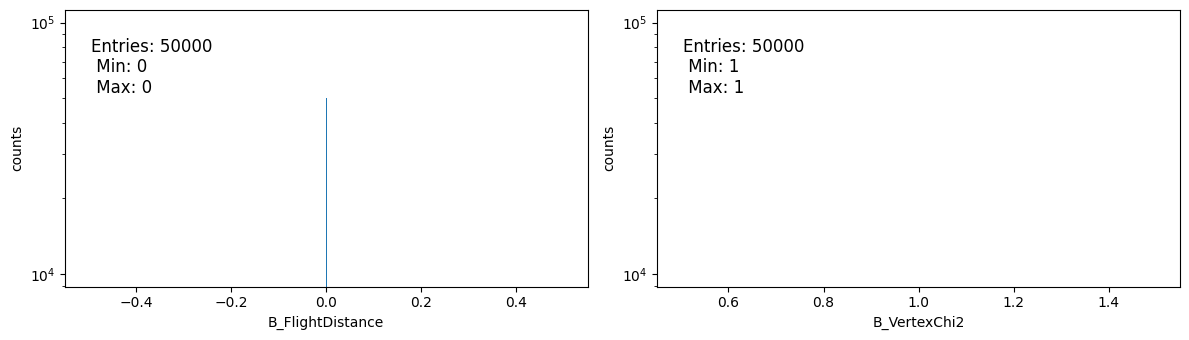

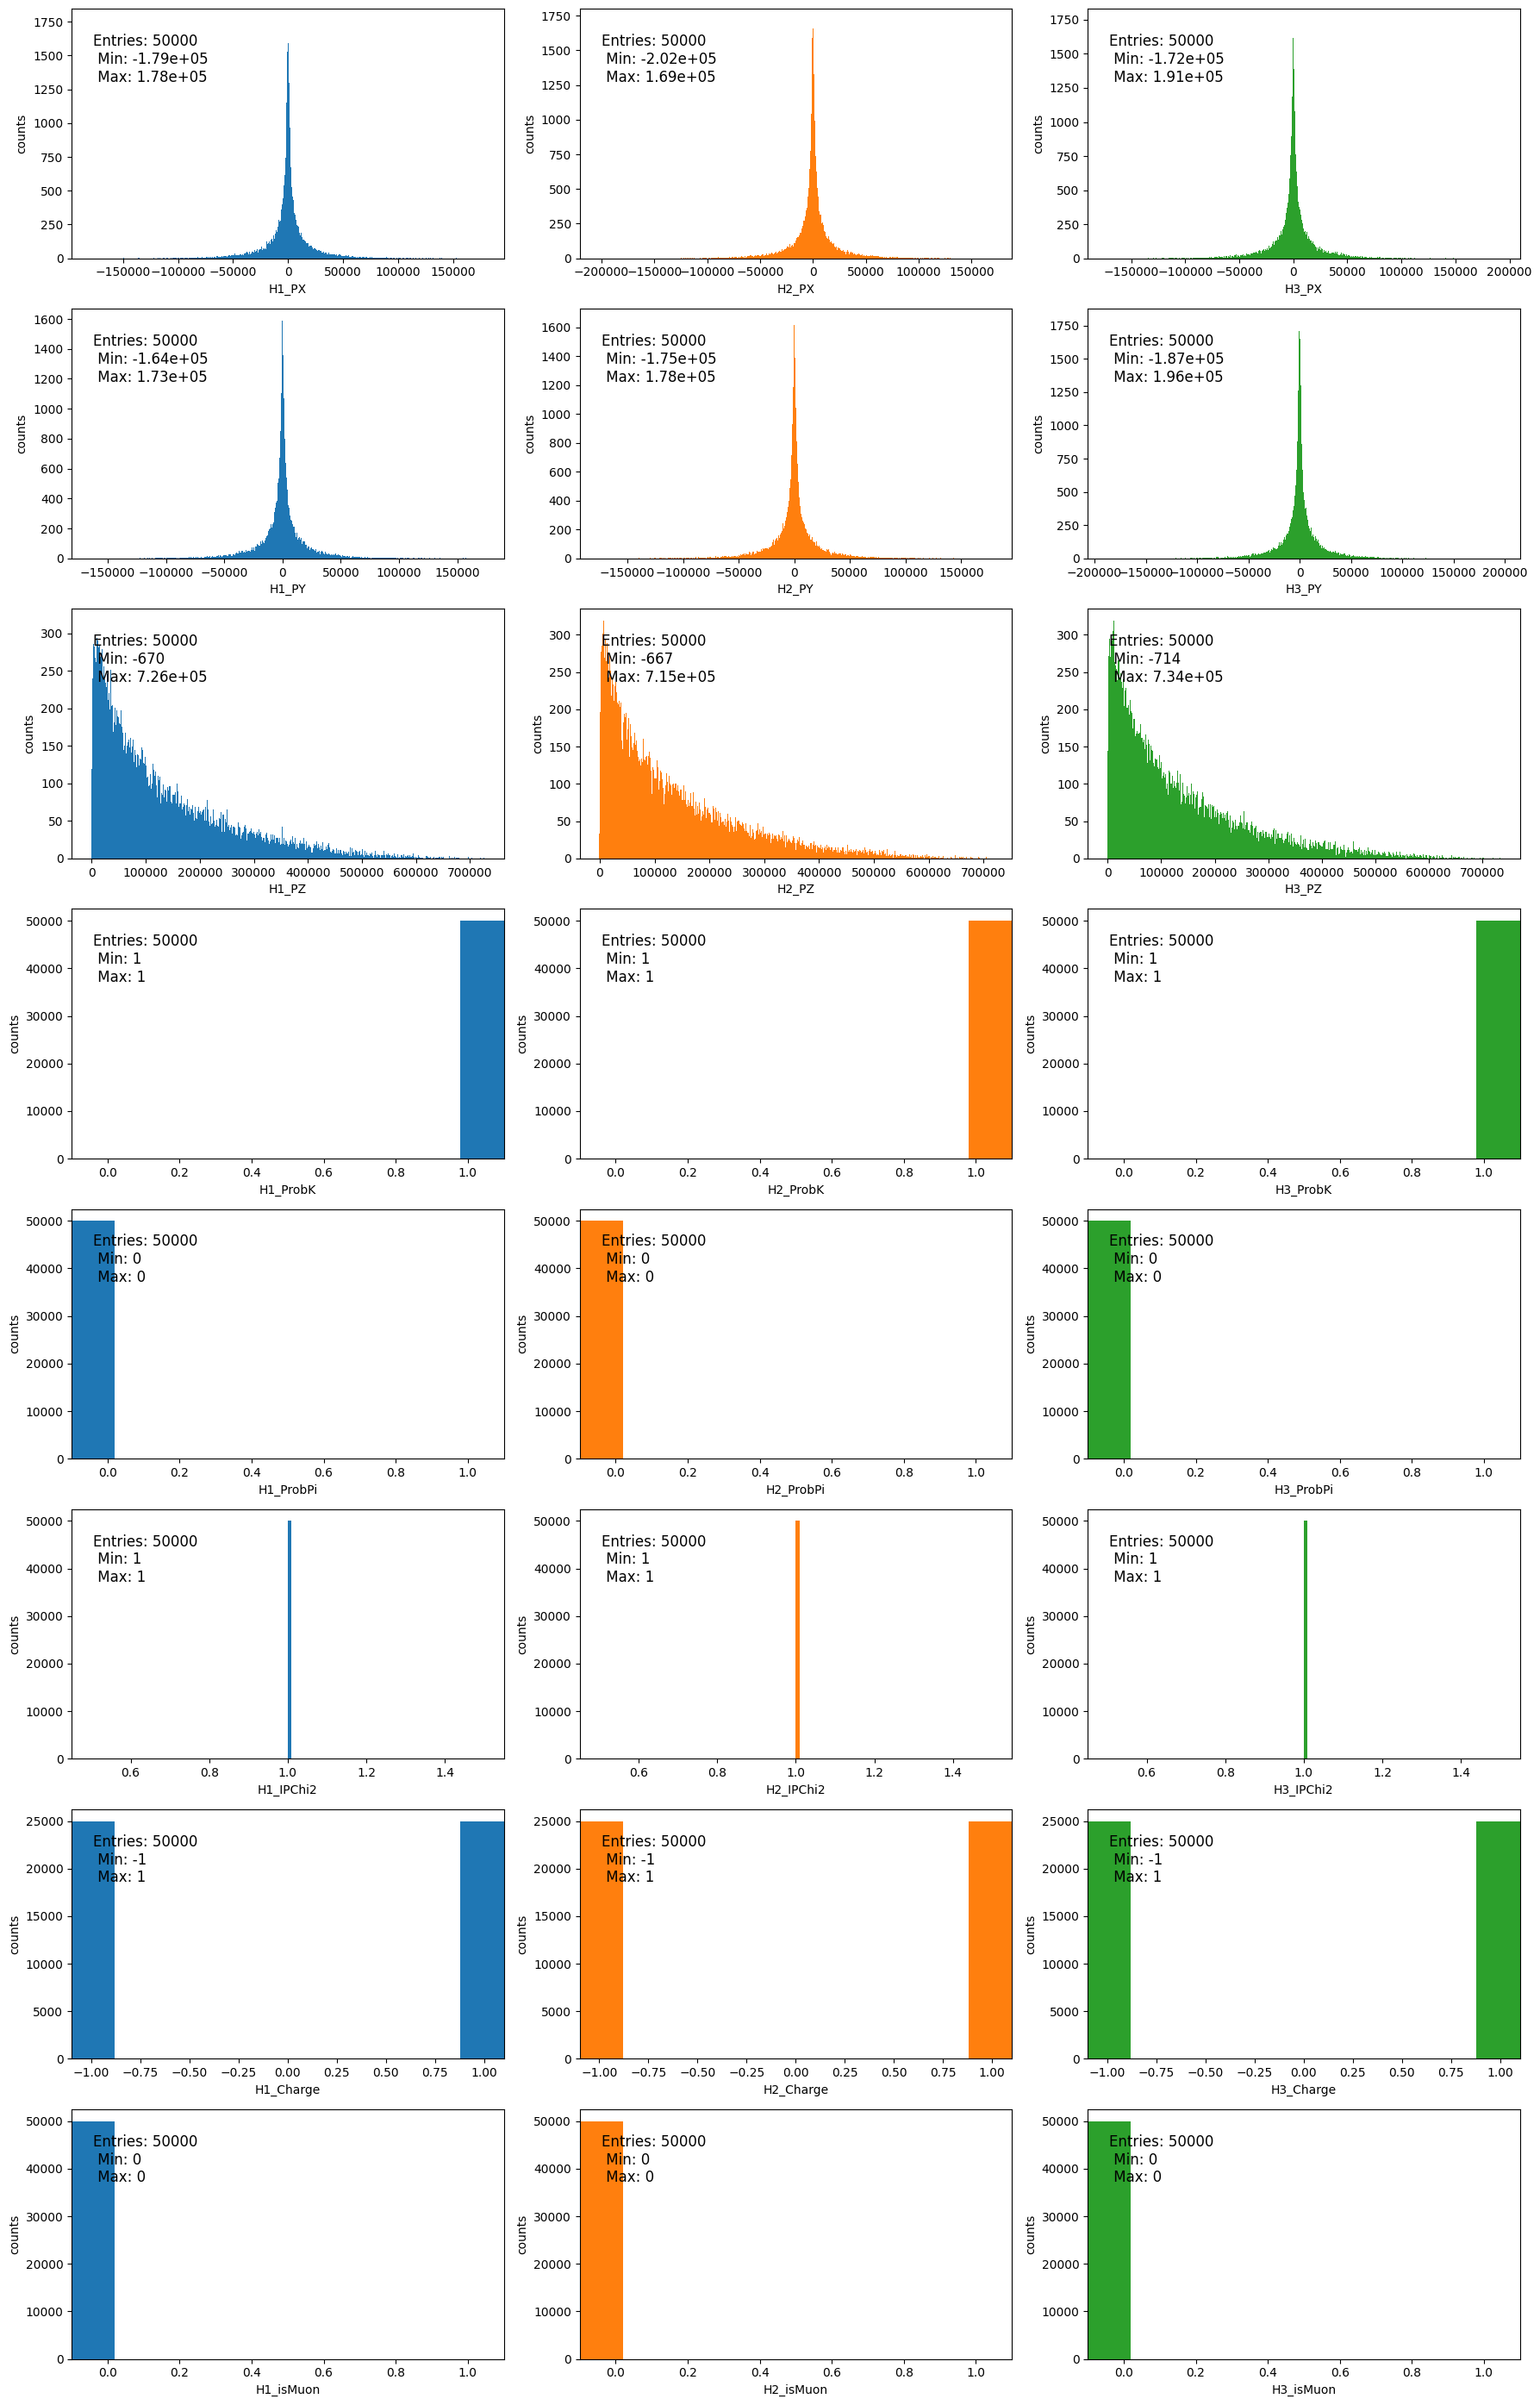

In [7]:
GLOBAL_FEATURES = ["B_FlightDistance", "B_VertexChi2"]
ORIGINAL_FEATURES = ["PX", "PY", "PZ", "ProbK", "ProbPi", "IPChi2", "Charge", "isMuon"]

products_features_settings_1 = {
    'PX': {'xlim': (None, None), 'bins': 1000},
    'PY': {'xlim': (None, None), 'bins': 1000},
    'PZ': {'xlim': (None, None), 'bins': 1000},
    'ProbK': {'xlim': (-0.1, 1.1), 'bins': 10},
    'ProbPi': {'xlim': (-0.1, 1.1), 'bins': 10},
    'Charge': {'xlim': (-1.1, 1.1), 'bins': 10},
    'IPChi2': {'xlim': (None, None), 'bins': 100},
    'isMuon': {'xlim': (-0.1, 1.1), 'bins': 10},
}

fig, axes = plot_all_features(df_sim_data, global_features=GLOBAL_FEATURES, products_features=ORIGINAL_FEATURES, products_features_settings=products_features_settings_1)

C:\Users\marco\AppData\Local\Temp\ipykernel_11436\720380314.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


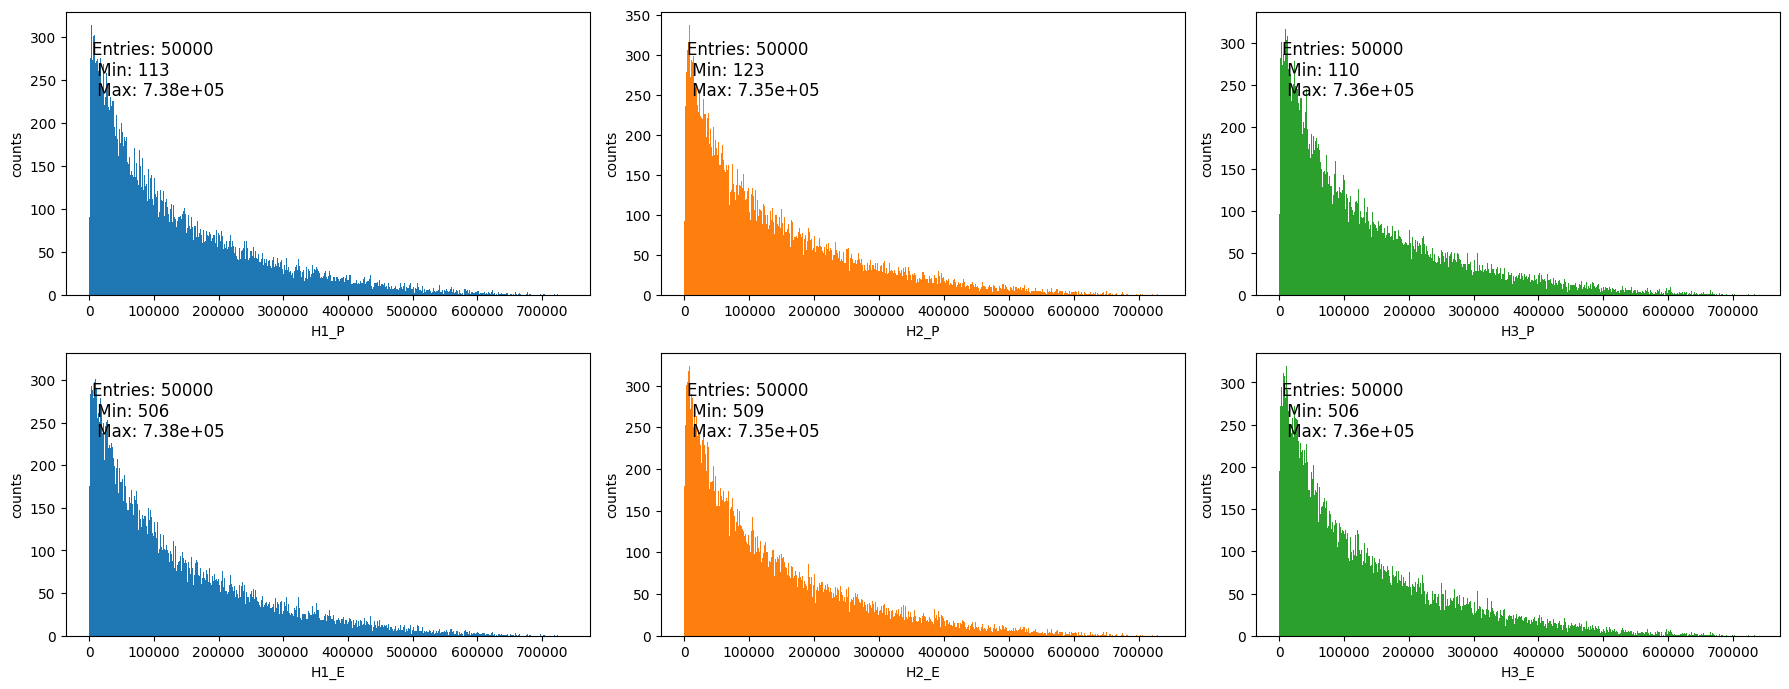

In [8]:
# New Features: Momentum magnitude + Energy --> not usefull...

number_of_products = 3
for j in range(number_of_products):
    mom3d = vector.array({'px': np.array(df_sim_data[f'H{j+1}_PX']), 'py': np.array(df_sim_data[f'H{j+1}_PY']), 'pz': np.array(df_sim_data[f'H{j+1}_PZ'])})
    df_sim_data[f'H{j+1}_P'] = mom3d.p
    
    mass_vector = np.ones(len(np.array(df_sim_data[f'H{j+1}_PX'])))*493.677
    mom4d = vector.array({'px': np.array(df_sim_data[f'H{j+1}_PX']), 'py': np.array(df_sim_data[f'H{j+1}_PY']), 'pz': np.array(df_sim_data[f'H{j+1}_PZ']), 'M': mass_vector})
    df_sim_data[f'H{j+1}_E'] = mom4d.energy
    
fig, axes = plot_all_features(df_sim_data, products_features=['P', 'E'], products_features_settings={'P': {'xlim': (None, None), 'bins': 1000}, 'E': {'xlim': (None, None), 'bins': 1000}})

### Compute Invariant Mass

In [9]:
# Compute total 4-momentum

mass_vector = np.ones(len(np.array(df_sim_data[f'H1_PX'])))*493.677

p1 = vector.array({'px': np.array(df_sim_data[f'H1_PX']), 'py': np.array(df_sim_data[f'H1_PY']), 'pz': np.array(df_sim_data[f'H1_PZ']), 'M': mass_vector})
p2 = vector.array({'px': np.array(df_sim_data[f'H2_PX']), 'py': np.array(df_sim_data[f'H2_PY']), 'pz': np.array(df_sim_data[f'H2_PZ']), 'M': mass_vector})
p3 = vector.array({'px': np.array(df_sim_data[f'H3_PX']), 'py': np.array(df_sim_data[f'H3_PY']), 'pz': np.array(df_sim_data[f'H3_PZ']), 'M': mass_vector})

pTot = p1 + p2 + p3

# B invariant mass
massB = pTot.mass

df_sim_data['B_Invariant_Mass'] = massB

print(p1[0])
print(p2[0])
print(p3[0])
print(pTot[0])

MomentumObject4D(px=3551.84, py=1636.96, pz=23904.14, mass=493.677)
MomentumObject4D(px=41507.15, py=15980.59, pz=331663.64, mass=493.677)
MomentumObject4D(px=36100.4, py=16546.83, pz=295600.61, mass=493.677)
MomentumObject4D(px=81159.39000000001, py=34164.380000000005, pz=651168.39, mass=5279.259021223659)


5279.278618323617
5279.279076658515


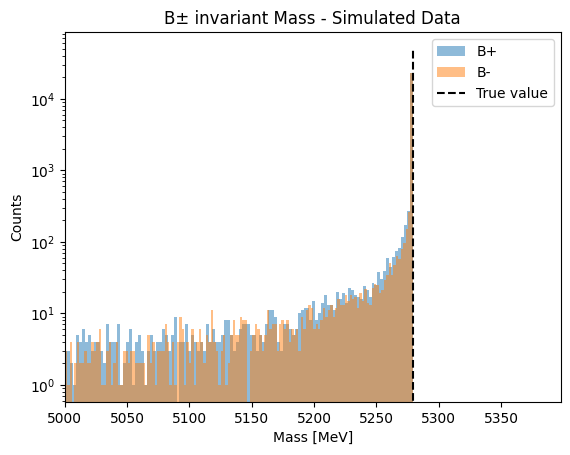

In [10]:
# Compute all charge (B charge)
totCharge = np.array(df_sim_data[f'H1_Charge']) + np.array(df_sim_data[f'H2_Charge']) + np.array(df_sim_data[f'H3_Charge'])

# Plot invariant mass for B+ and B-
for charge in [+1, -1]:
    mask = (totCharge == charge)
    y, x = np.histogram(massB[mask], bins=1000)
    print(np.max(x))

    plt.hist(massB[mask], bins=1000, alpha=0.5, label='B+' if charge==1 else 'B-')
    # plt.plot((x[:-1]+x[1:])/2, y)
    
plt.vlines(5279.15, 0, 50000, linestyles='--', color='k', label='True value')
plt.yscale('log')
plt.xlim(left = 5000)
plt.title("B± invariant Mass - Simulated Data")
plt.xlabel("Mass [MeV]")
plt.ylabel("Counts")
plt.legend()
plt.show()

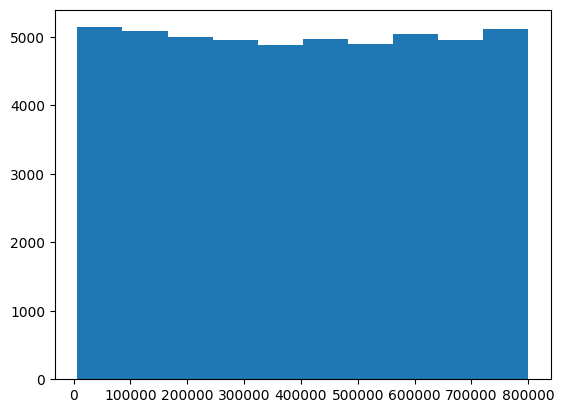

In [11]:
lenght = len(np.array(df_sim_data['H1_PX']))
E1 = np.sqrt(np.array(df_sim_data['H1_PX'])**2 + np.array(df_sim_data['H1_PY'])**2 + np.array(df_sim_data['H1_PZ'])**2 + (np.ones(lenght)*493.677)**2)
E2 = np.sqrt(np.array(df_sim_data['H2_PX'])**2 + np.array(df_sim_data['H2_PY'])**2 + np.array(df_sim_data['H2_PZ'])**2 + (np.ones(lenght)*493.677)**2)
E3 = np.sqrt(np.array(df_sim_data['H3_PX'])**2 + np.array(df_sim_data['H3_PY'])**2 + np.array(df_sim_data['H3_PZ'])**2 + (np.ones(lenght)*493.677)**2)

E_tot = E1 + E2 + E3

plt.hist(E_tot);

In [12]:
px_tot = np.array(df_sim_data['H1_PX']) + np.array(df_sim_data['H2_PX']) + np.array(df_sim_data['H3_PX'])
py_tot = np.array(df_sim_data['H1_PY']) + np.array(df_sim_data['H2_PY']) + np.array(df_sim_data['H3_PY'])
pz_tot = np.array(df_sim_data['H1_PZ']) + np.array(df_sim_data['H2_PZ']) + np.array(df_sim_data['H3_PZ'])

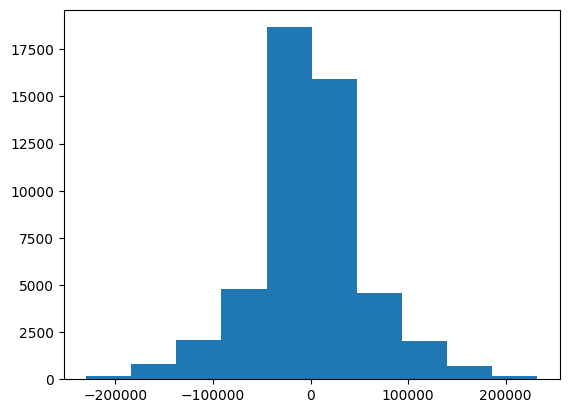

In [13]:
plt.hist(px_tot);

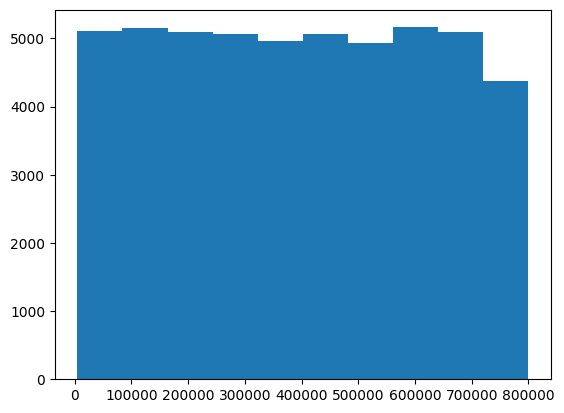

In [14]:
plt.hist(pz_tot);

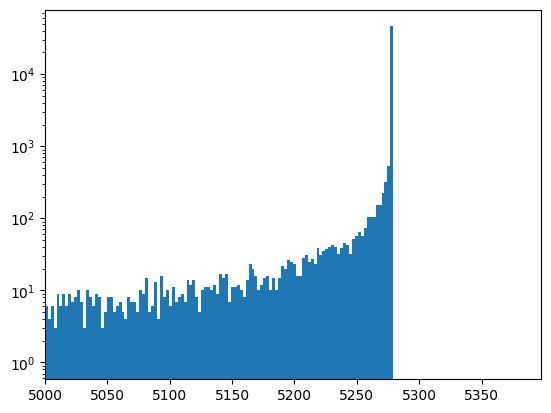

In [15]:
m_tot = np.sqrt(E_tot**2 - (px_tot**2 + py_tot**2 + pz_tot**2) )
plt.hist(m_tot, bins=1000);
plt.xlim(left=5000)
plt.yscale('log')

# Real Data

#### Load Data

In [16]:
DATA_DIR = r"C:\\Users\\marco\\Documents\\Università\\Anno IV\\Statistics_and_Data_Analysis\\"
FILES = [f"{DATA_DIR}/B2HHH_MagnetDown.root", f"{DATA_DIR}/B2HHH_MagnetUp.root"]

BRANCHES = [f"H{i}_{v}" for i in (1, 2, 3)
            for v in ("PX", "PY", "PZ", "ProbK", "ProbPi", "isMuon", "Charge")]

frames = []
for path in FILES:
    with uproot.open(path) as f:
        tree = f["DecayTree"]
        arrs = tree.arrays(library="pd")
    arrs["magnet"] = "down" if "Down" in path else "up"
    frames.append(arrs)

all_data = pd.concat(frames, ignore_index=True)
print("total events read:", len(all_data))

total events read: 8556118


In [17]:
all_data.head()

,B_FlightDistance,B_VertexChi2,H1_PX,H1_PY,H1_PZ,H1_ProbK,H1_ProbPi,H1_Charge,H1_IPChi2,H1_isMuon,...,H2_isMuon,H3_PX,H3_PY,H3_PZ,H3_ProbK,H3_ProbPi,H3_Charge,H3_IPChi2,H3_isMuon,magnet
0,25.301004,1.497280,375.284205,831.308481,51820.233718,0.038616,0.888755,-1,212.776776,0,...,0,-208.210960,-2586.359121,105848.271681,0.193004,0.138845,1,61.157888,1,down
1,94.690700,1.383338,-4985.130785,5853.750057,326157.454706,0.073556,0.039064,-1,373.815885,1,...,1,-175.018535,1325.178792,87681.561846,0.080397,0.758603,1,185.092016,0,down
2,8.284490,5.187101,-1265.456544,2330.050788,90762.658032,0.030095,0.636693,1,53.187855,0,...,0,-1383.996490,-71.081104,85574.929582,0.750751,0.399602,-1,1.481413,0,down
3,5.590769,7.129099,-720.797259,3413.790588,86793.058768,0.211414,0.350969,-1,6.232666,0,...,0,398.775944,-1134.914464,14653.316611,0.005698,0.964705,1,468.174038,0,down
4,3.013242,10.988701,397.754571,1791.373059,40040.364159,0.005697,0.933102,-1,3.137287,0,...,0,477.148467,2113.439057,24462.076980,0.002979,0.918983,1,60.530372,0,down


In [18]:
all_data.columns

Index(['B_FlightDistance', 'B_VertexChi2', 'H1_PX', 'H1_PY', 'H1_PZ',
       'H1_ProbK', 'H1_ProbPi', 'H1_Charge', 'H1_IPChi2', 'H1_isMuon', 'H2_PX',
       'H2_PY', 'H2_PZ', 'H2_ProbK', 'H2_ProbPi', 'H2_Charge', 'H2_IPChi2',
       'H2_isMuon', 'H3_PX', 'H3_PY', 'H3_PZ', 'H3_ProbK', 'H3_ProbPi',
       'H3_Charge', 'H3_IPChi2', 'H3_isMuon', 'magnet'],
      dtype='str')

#### Data Exploration

C:\Users\marco\AppData\Local\Temp\ipykernel_11436\720380314.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
C:\Users\marco\AppData\Local\Temp\ipykernel_11436\720380314.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


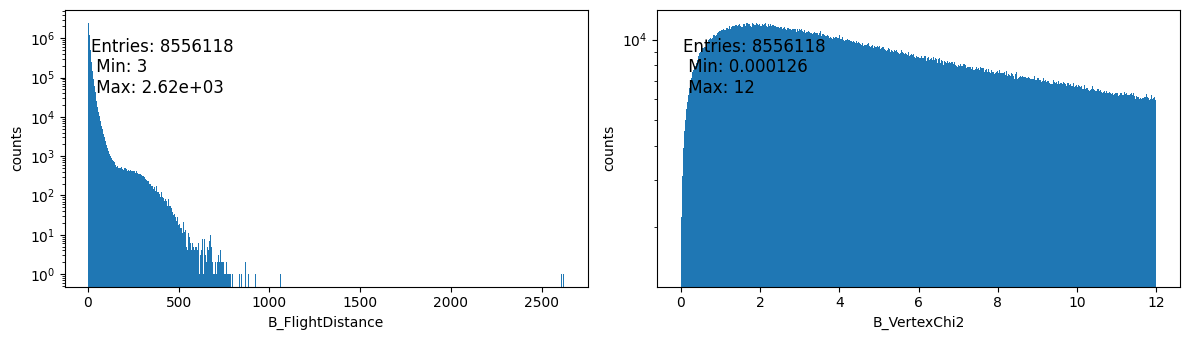

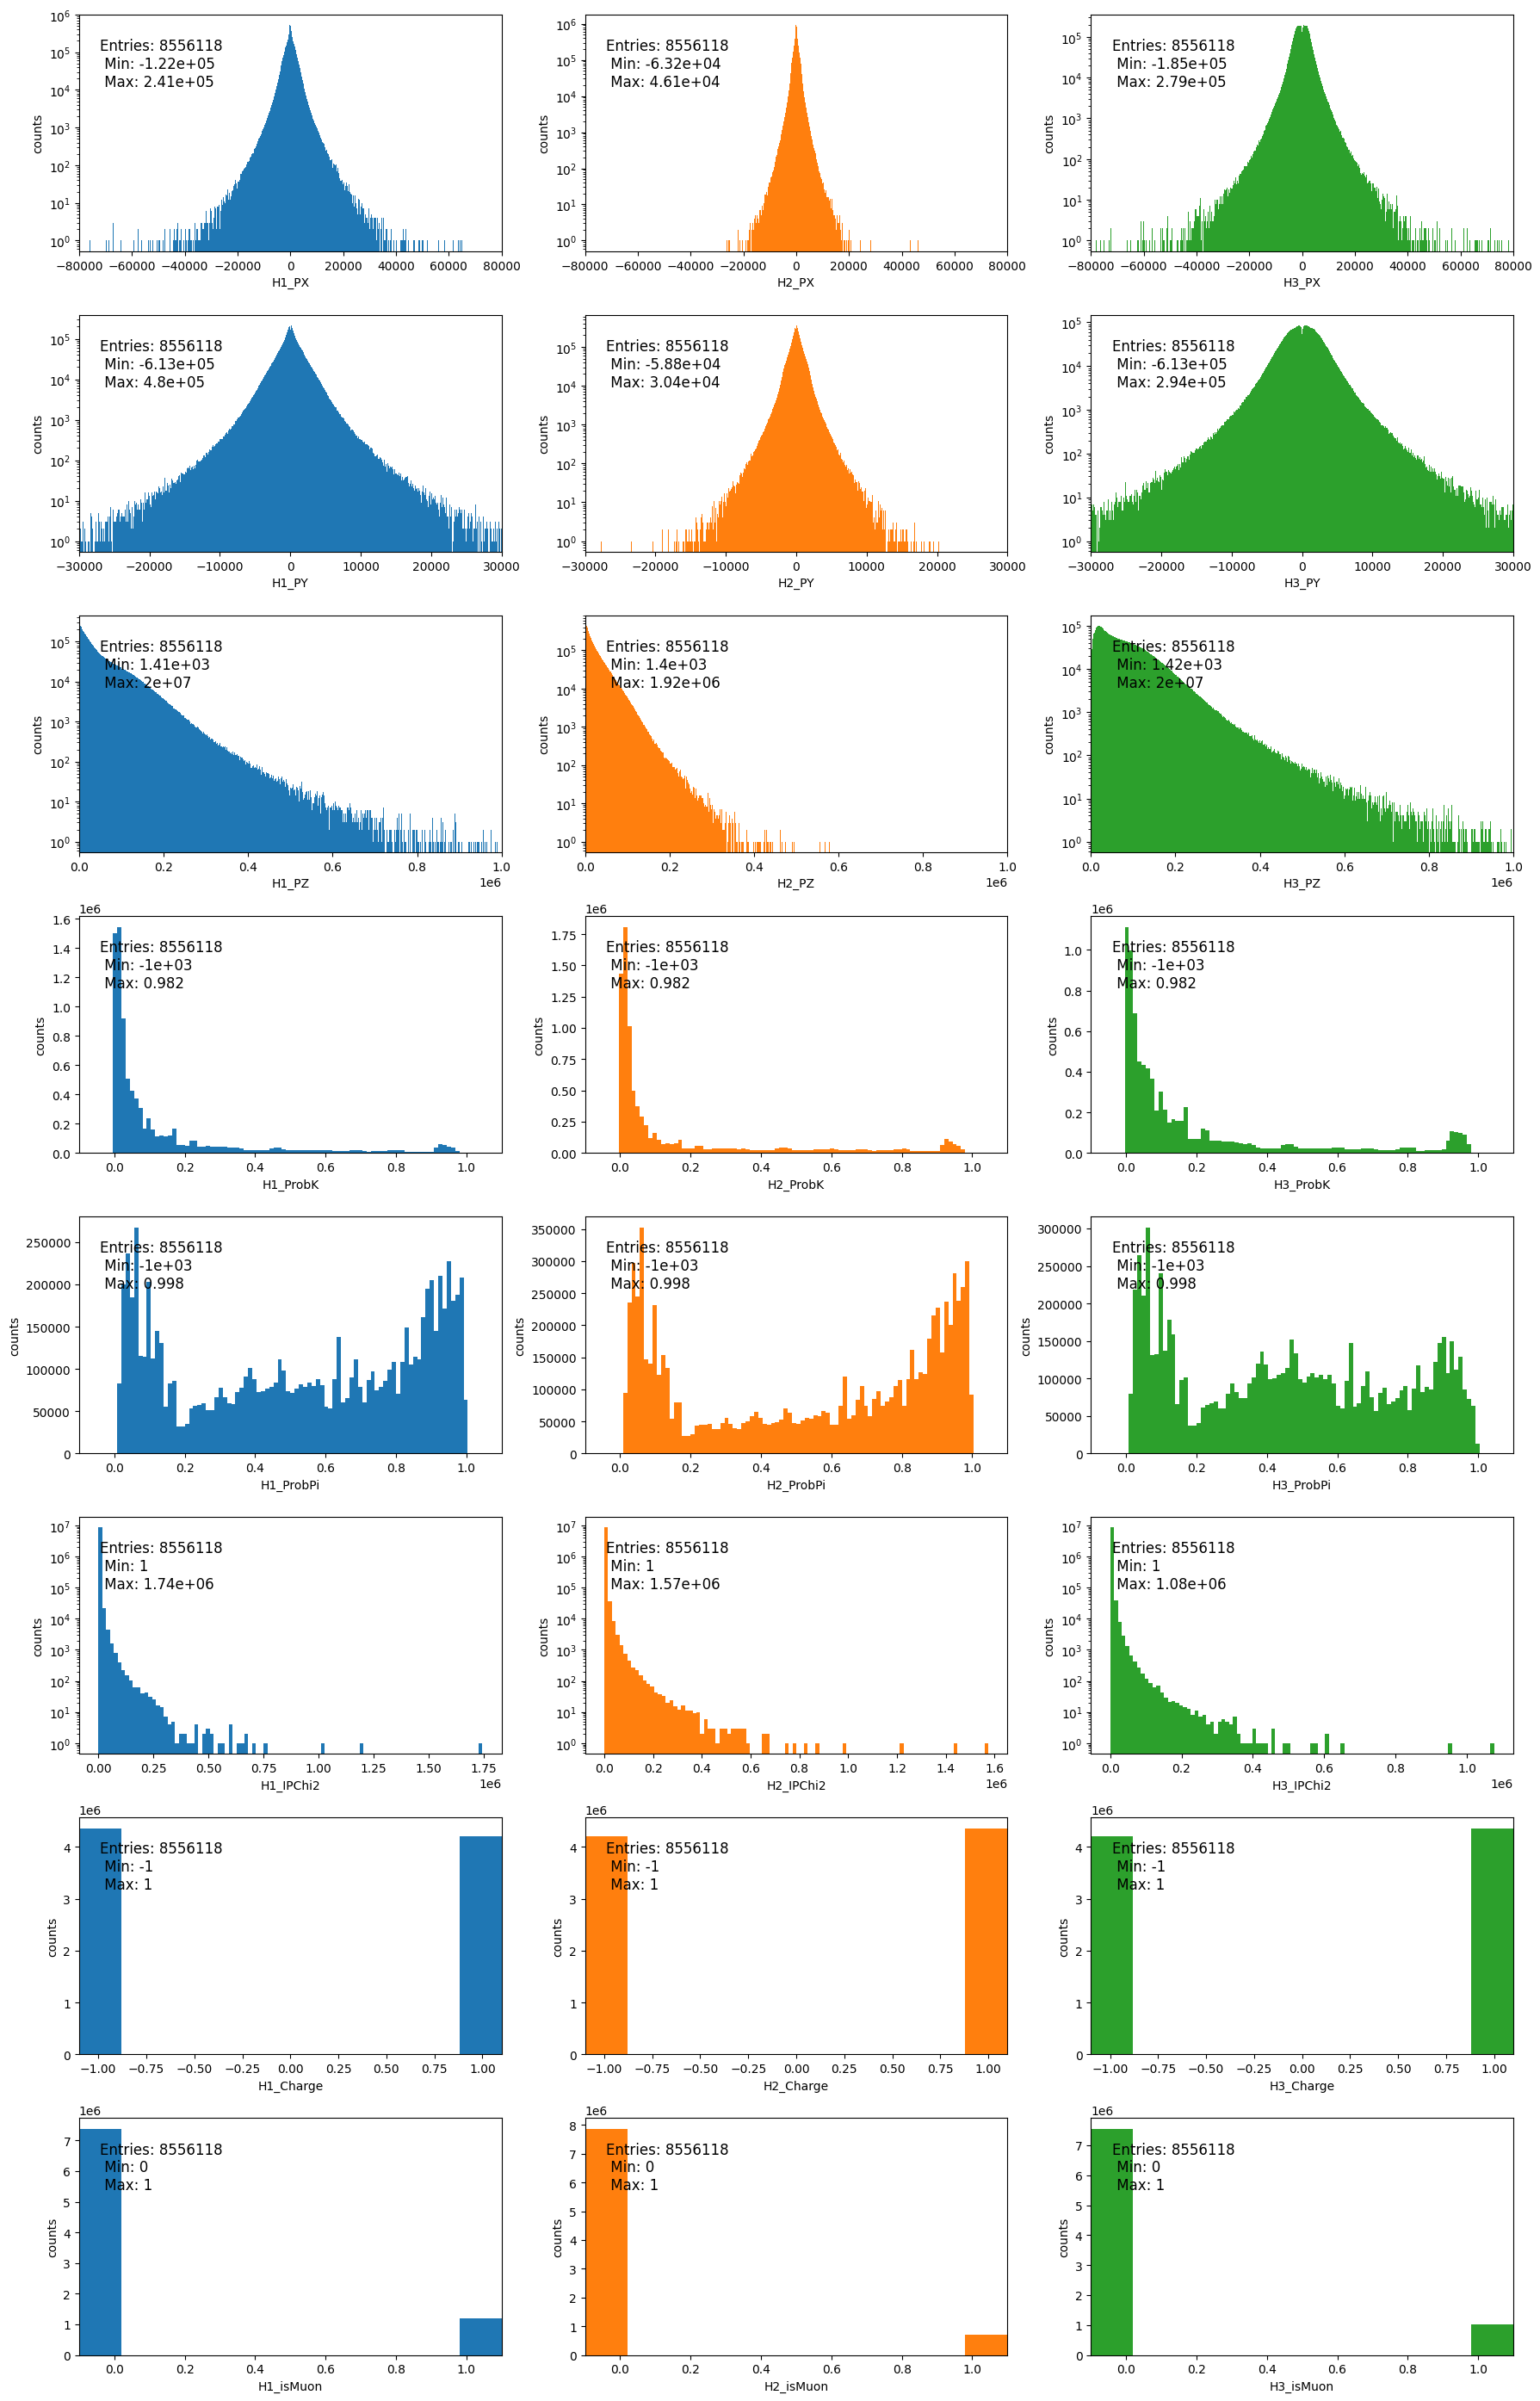

In [19]:
GLOBAL_FEATURES = ["B_FlightDistance", "B_VertexChi2"]
PRODUCTS_FEATURES = ["PX", "PY", "PZ", "ProbK", "ProbPi", 'IPChi2', "Charge", "isMuon"]

products_features_settings_2 = {
    'PX': {'xlim': (-80_000, +80_000), 'bins': 1000, 'log_y': True},
    'PY': {'xlim': (-30_000, +30_000), 'bins': 1000, 'log_y': True},
    'PZ': {'xlim': (0, 1e6), 'bins': 1000, 'log_y': True},
    'ProbK': {'xlim': (-0.1, 1.1), 'bins': 100, 'log_y': False},
    'ProbPi': {'xlim': (-0.1, 1.1), 'bins': 100, 'log_y': False},
    'Charge': {'xlim': (-1.1, 1.1), 'bins': 10, 'log_y': False},
    'IPChi2': {'xlim': (None, None), 'bins': 100, 'log_y': True},
    'isMuon': {'xlim': (-0.1, 1.1), 'bins': 10, 'log_y': False},
}

fig, axes = plot_all_features(all_data, global_features=GLOBAL_FEATURES, products_features=PRODUCTS_FEATURES, products_features_settings=products_features_settings_2)

In [20]:
# remove useless columns
column_to_drop = [col for col in all_data.columns if col not in BRANCHES and col != "magnet"]
data = all_data
data.drop(columns=column_to_drop, inplace=True)
print(data.columns)
data.head()

Index(['H1_PX', 'H1_PY', 'H1_PZ', 'H1_ProbK', 'H1_ProbPi', 'H1_Charge',
       'H1_isMuon', 'H2_PX', 'H2_PY', 'H2_PZ', 'H2_ProbK', 'H2_ProbPi',
       'H2_Charge', 'H2_isMuon', 'H3_PX', 'H3_PY', 'H3_PZ', 'H3_ProbK',
       'H3_ProbPi', 'H3_Charge', 'H3_isMuon', 'magnet'],
      dtype='str')


,H1_PX,H1_PY,H1_PZ,H1_ProbK,H1_ProbPi,H1_Charge,H1_isMuon,H2_PX,H2_PY,H2_PZ,...,H2_Charge,H2_isMuon,H3_PX,H3_PY,H3_PZ,H3_ProbK,H3_ProbPi,H3_Charge,H3_isMuon,magnet
0,375.284205,831.308481,51820.233718,0.038616,0.888755,-1,0,708.073133,-1098.156476,17678.307346,...,1,0,-208.210960,-2586.359121,105848.271681,0.193004,0.138845,1,1,down
1,-4985.130785,5853.750057,326157.454706,0.073556,0.039064,-1,1,144.300886,85.205300,5324.123346,...,1,1,-175.018535,1325.178792,87681.561846,0.080397,0.758603,1,0,down
2,-1265.456544,2330.050788,90762.658032,0.030095,0.636693,1,0,-739.506324,-1036.736792,17885.000646,...,-1,0,-1383.996490,-71.081104,85574.929582,0.750751,0.399602,-1,0,down
3,-720.797259,3413.790588,86793.058768,0.211414,0.350969,-1,0,-381.169232,1081.069786,20276.393591,...,1,0,398.775944,-1134.914464,14653.316611,0.005698,0.964705,1,0,down
4,397.754571,1791.373059,40040.364159,0.005697,0.933102,-1,0,1841.069628,-794.103213,11610.344506,...,1,0,477.148467,2113.439057,24462.076980,0.002979,0.918983,1,0,down


C:\Users\marco\AppData\Local\Temp\ipykernel_11436\720380314.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


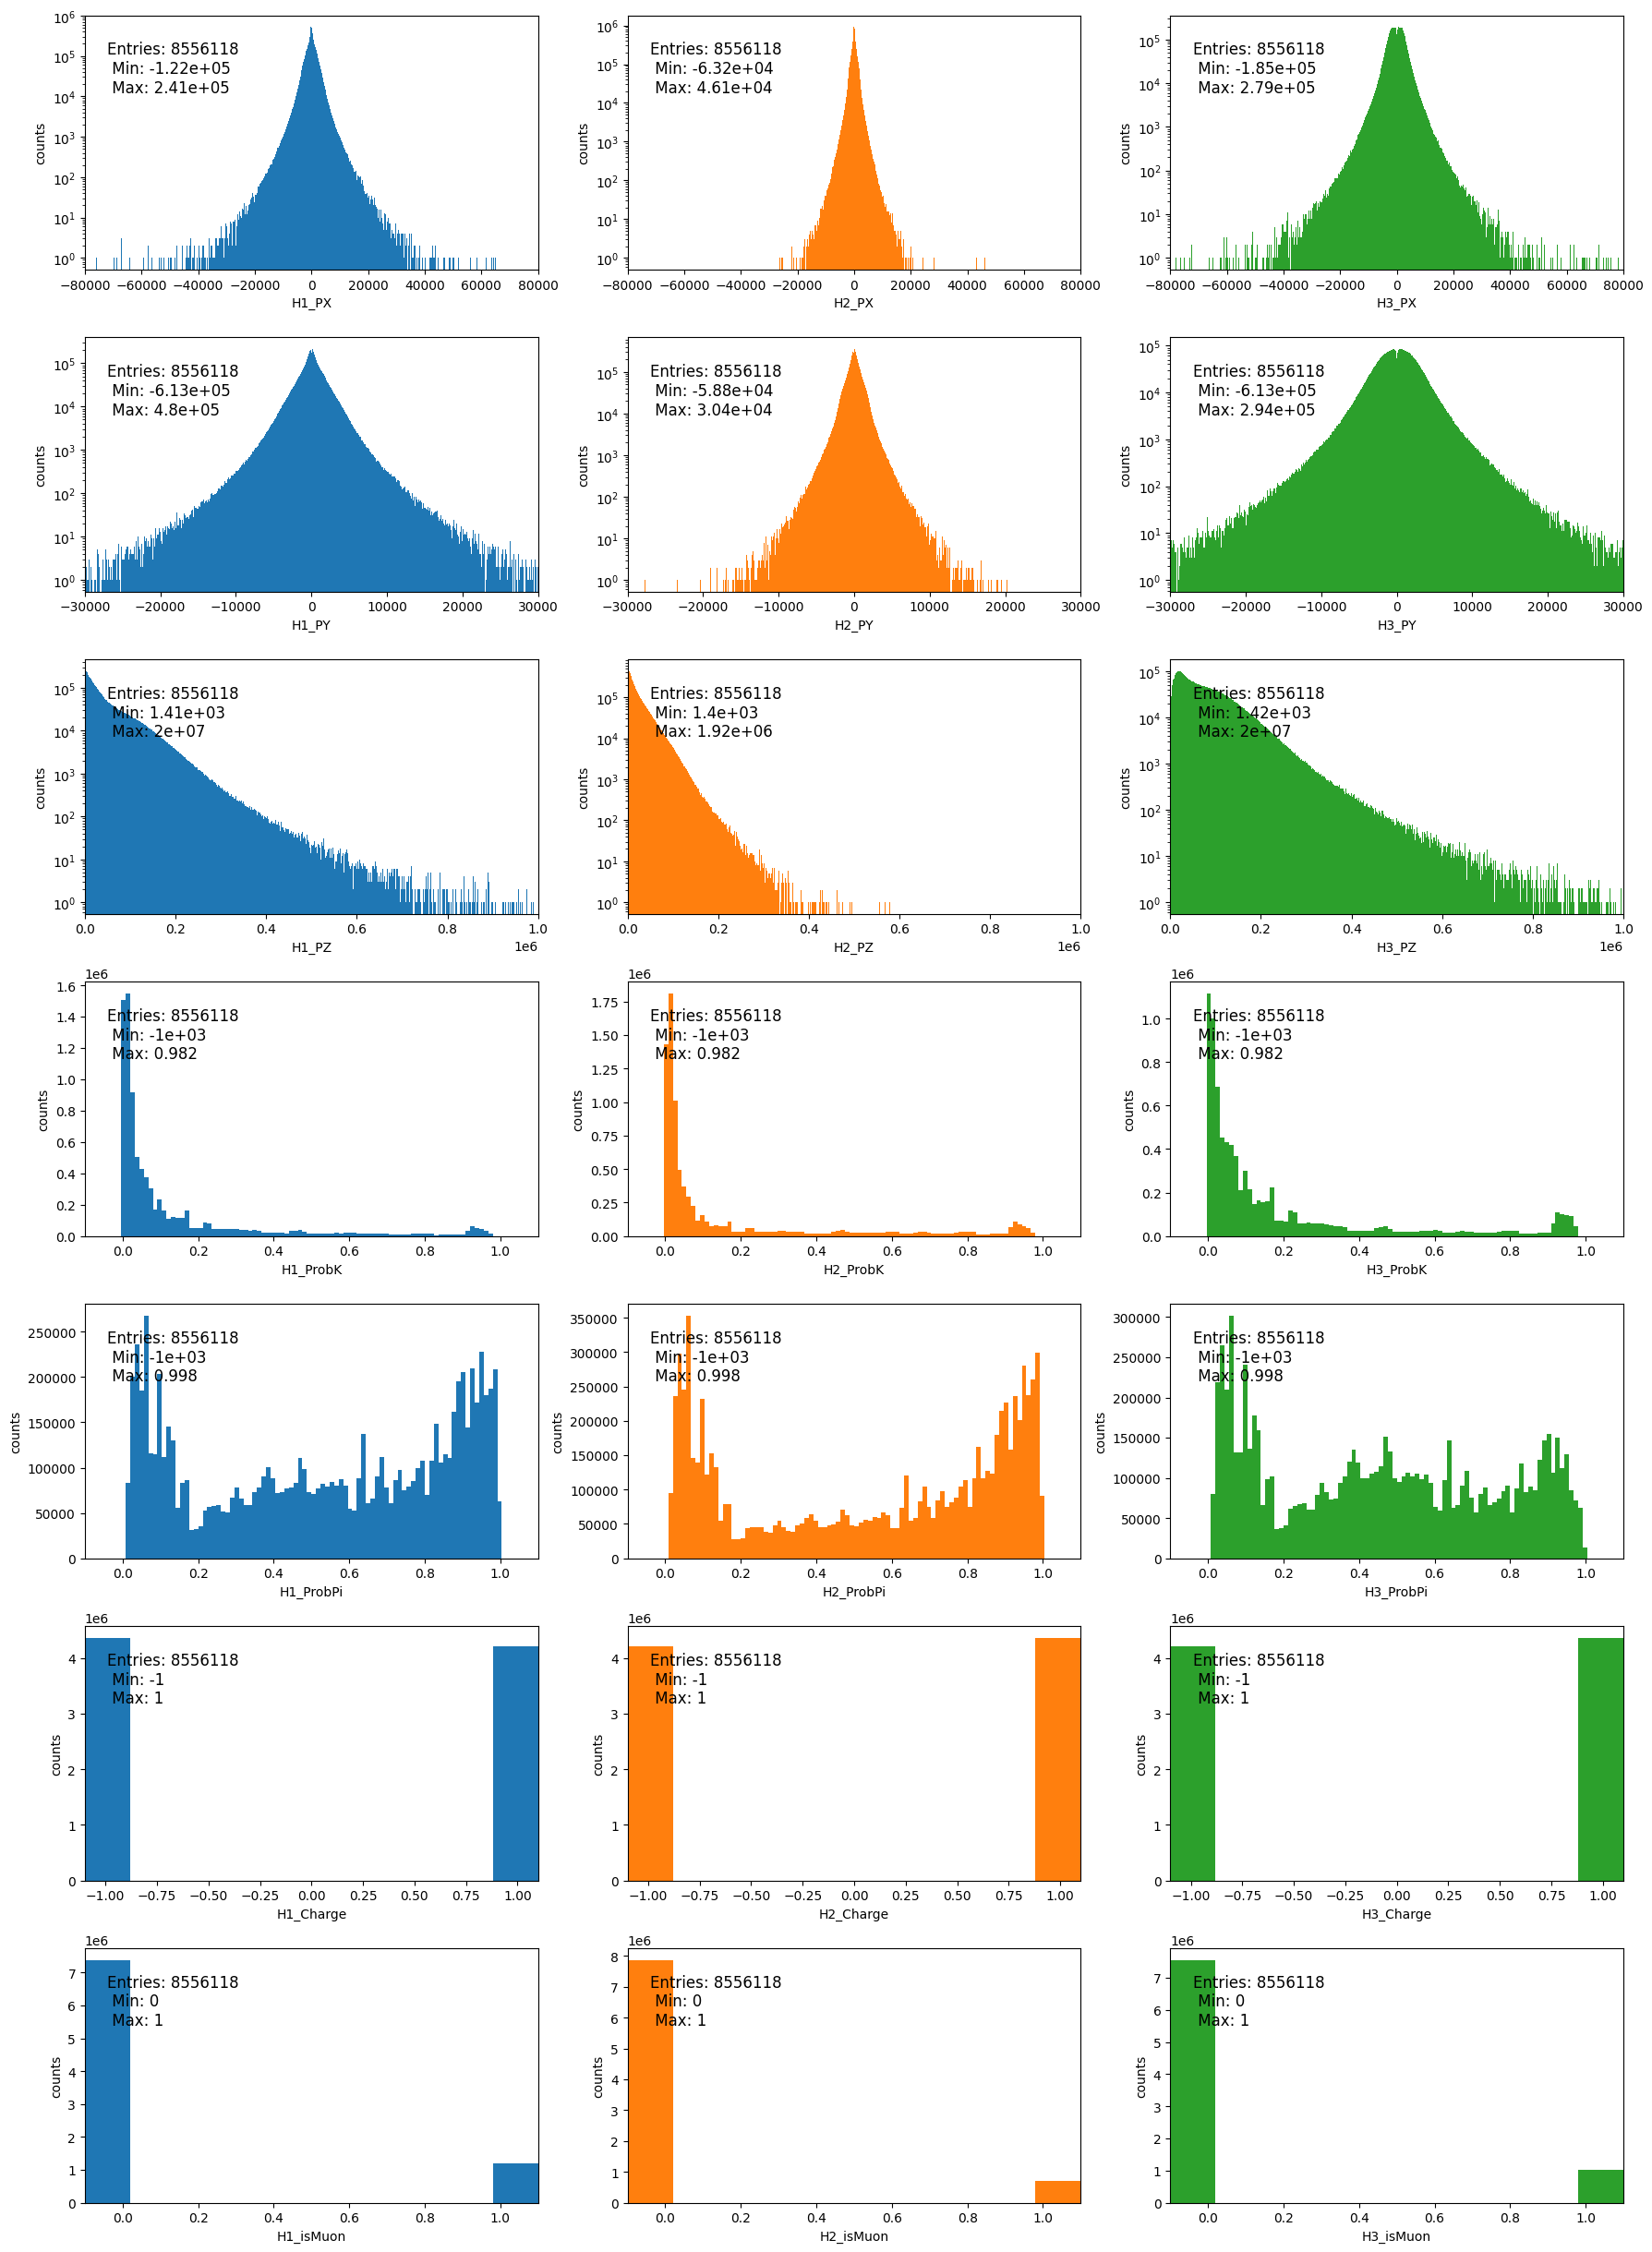

In [21]:
PRODUCTS_FEATURES = ["PX", "PY", "PZ", "ProbK", "ProbPi", "Charge", "isMuon"]

fig, ax = plot_all_features(data, products_features=PRODUCTS_FEATURES, products_features_settings=products_features_settings_2)

### Preselection

In [22]:
# Preselection for  B -> KKK
preselection = np.logical_and.reduce((
        np.less(data['H1_ProbPi'], 0.5),
        np.less(data['H2_ProbPi'], 0.5),
        np.less(data['H3_ProbPi'], 0.5),
        np.greater(data['H1_ProbK'], 0.5),
        np.greater(data['H2_ProbK'], 0.5),
        np.greater(data['H3_ProbK'], 0.5),
        np.equal(data['H1_isMuon'], 0),
        np.equal(data['H2_isMuon'], 0),
        np.equal(data['H3_isMuon'], 0)
    ))

C:\Users\marco\AppData\Local\Temp\ipykernel_11436\720380314.py:45: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


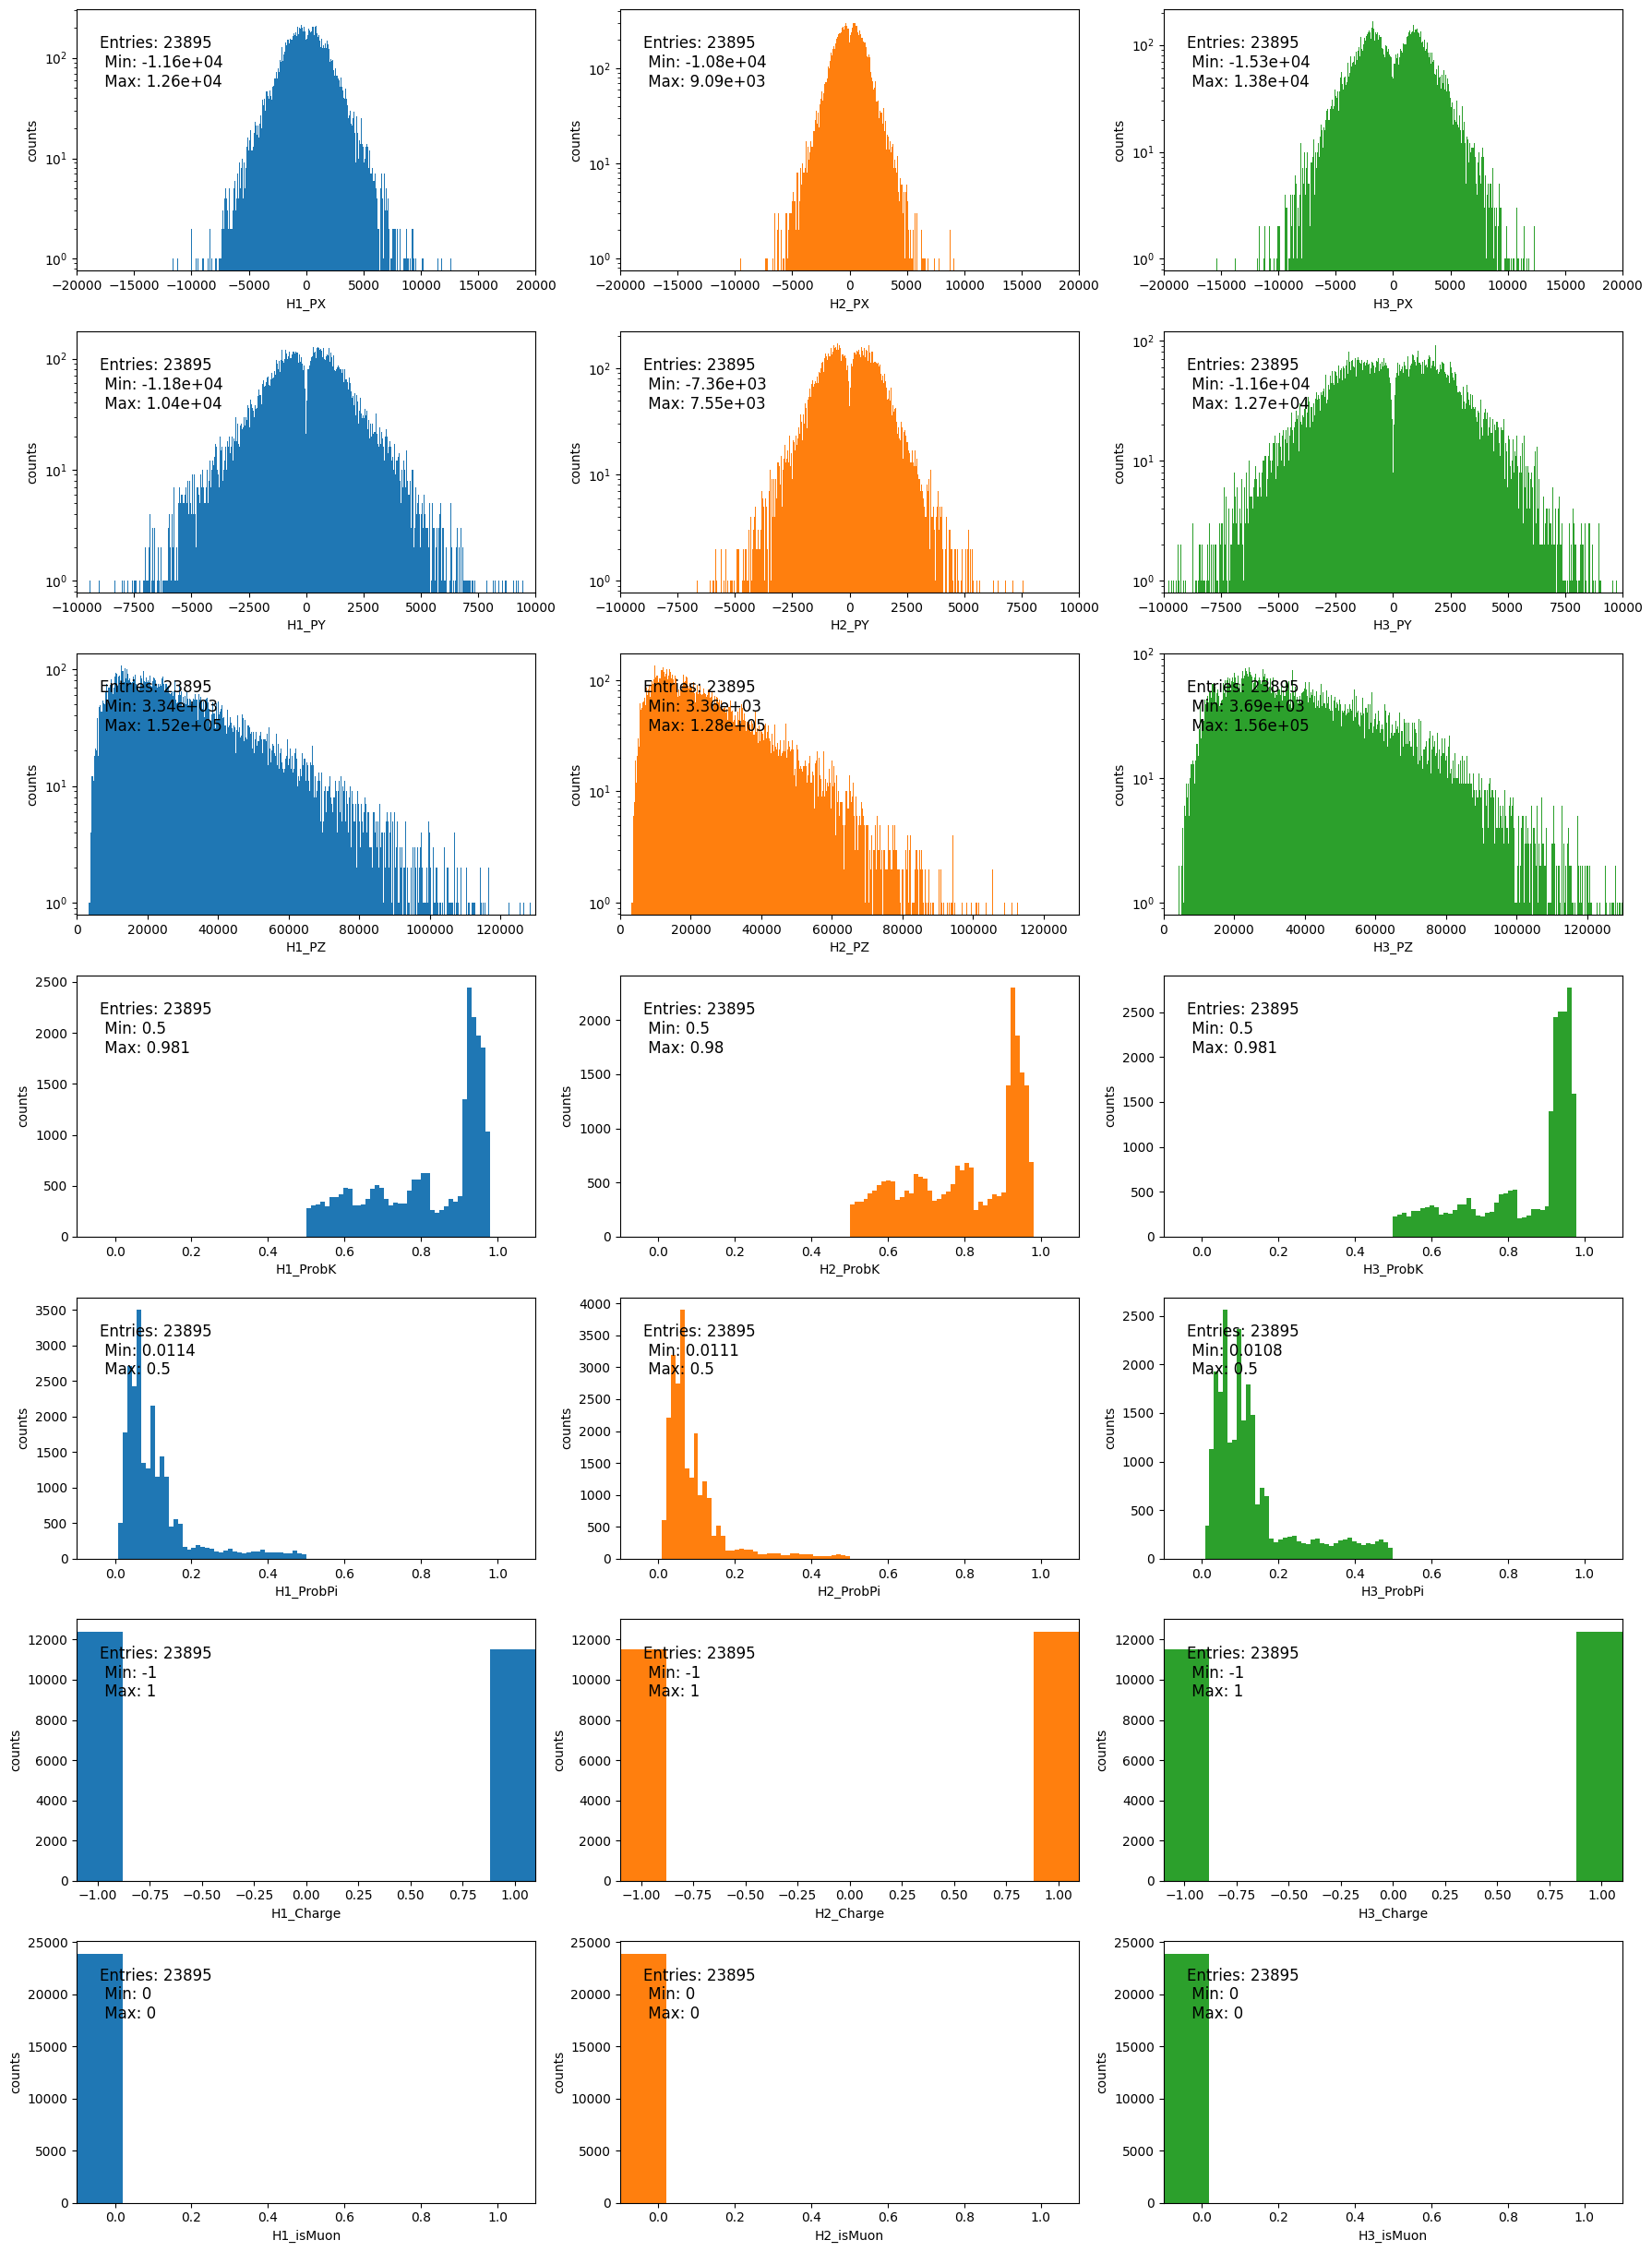

In [23]:
PRODUCTS_FEATURES = ["PX", "PY", "PZ", "ProbK", "ProbPi", "Charge", "isMuon"]

products_features_settings_3 = {
    'PX': {'xlim': (-20_000, +20_000), 'bins': 1000, 'log_y': True},
    'PY': {'xlim': (-10_000, +10_000), 'bins': 1000, 'log_y': True},
    'PZ': {'xlim': (0, 0.13e6), 'bins': 1000, 'log_y': True},
    'ProbK': {'xlim': (-0.1, 1.1), 'bins': 100, 'log_y': False},
    'ProbPi': {'xlim': (-0.1, 1.1), 'bins': 100, 'log_y': False},
    'Charge': {'xlim': (-1.1, 1.1), 'bins': 10, 'log_y': False},
    'isMuon': {'xlim': (-0.1, 1.1), 'bins': 10, 'log_y': False},
}

fig, ax = plot_all_features(data[preselection], products_features=PRODUCTS_FEATURES, products_features_settings=products_features_settings_3)

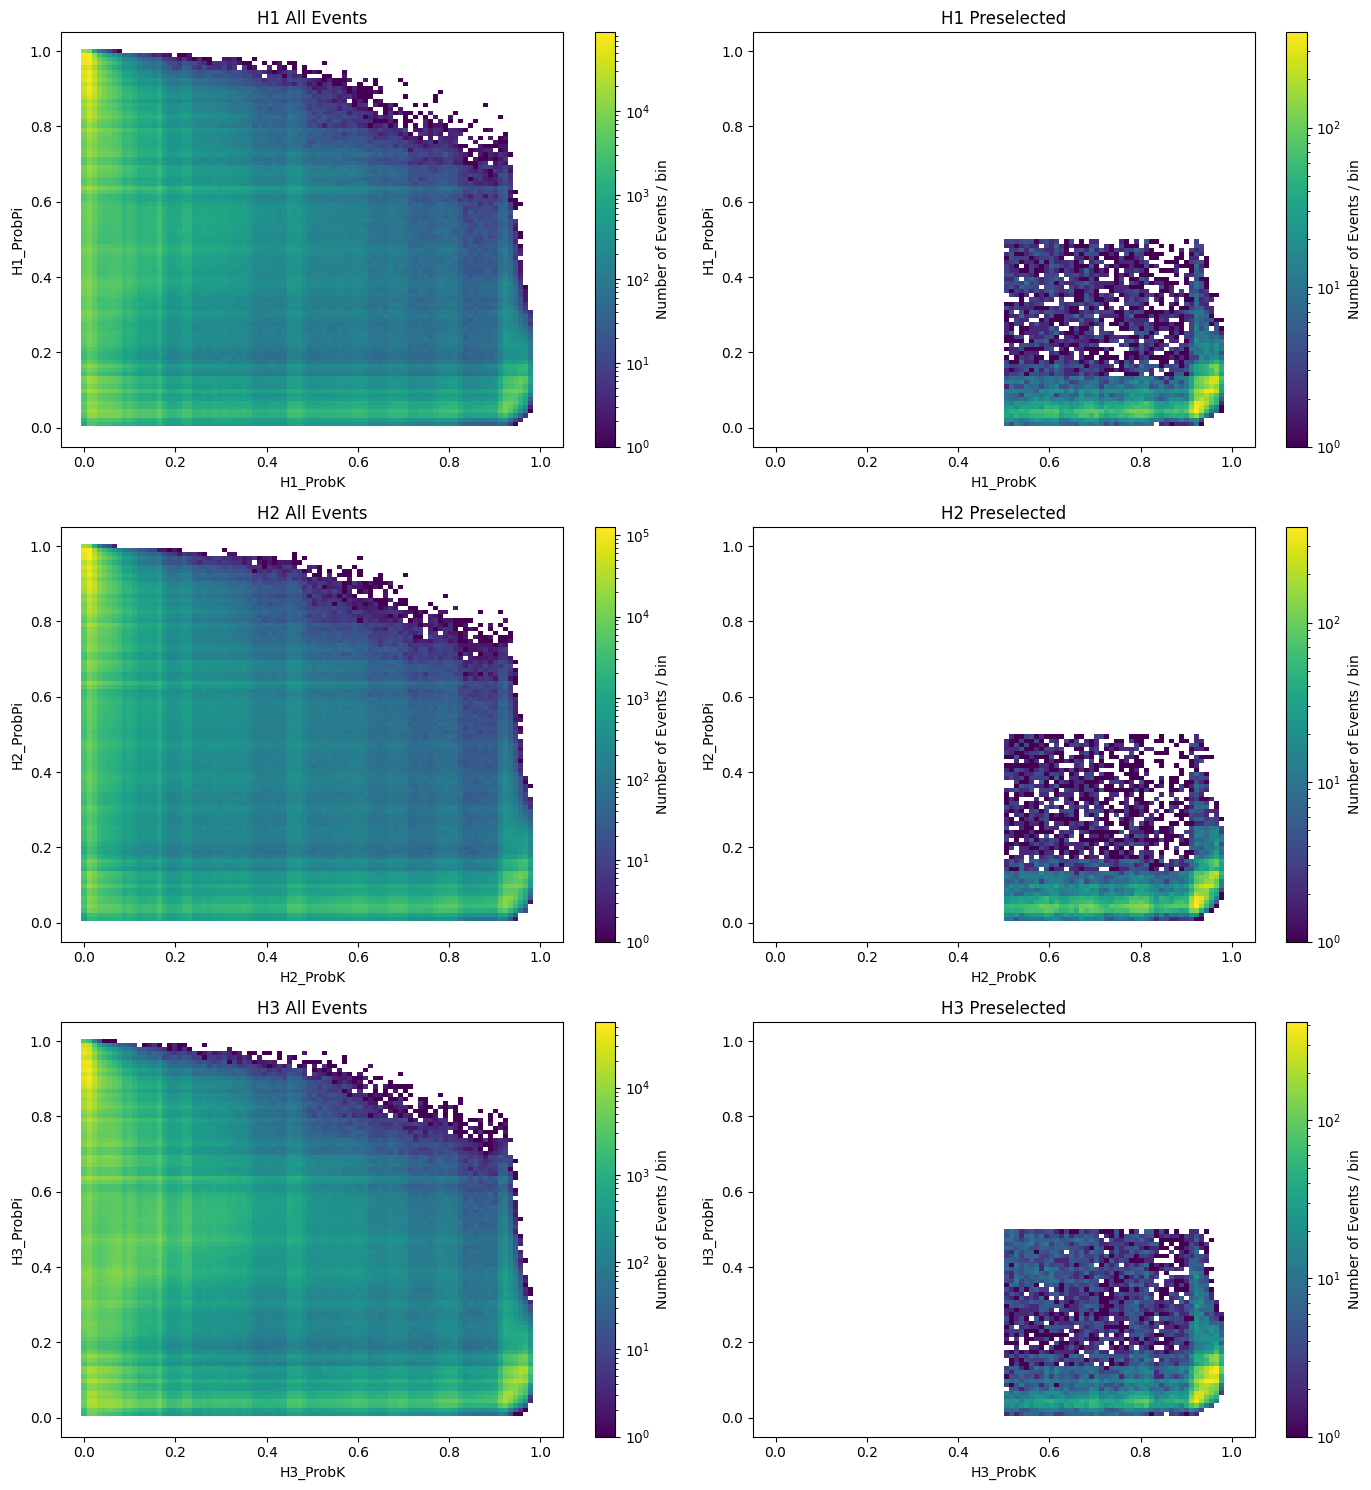

In [24]:
# 2D plot of ProbK and ProbPi

fig, axes = plt.subplots(number_of_products, 2, figsize=(14, 5*number_of_products))

if number_of_products == 1:
    axes = [axes]

for j in range(number_of_products):
    # --- Original Data ---
    h0, xedges0, yedges0, im0 = axes[j][0].hist2d(
        data[f'H{j+1}_ProbK'], 
        data[f'H{j+1}_ProbPi'], 
        bins=100,
        range=[[-0.05, 1.05], [-0.05, 1.05]],
        norm=LogNorm()
    )
    axes[j][0].set_xlabel(f'H{j+1}_ProbK')
    axes[j][0].set_ylabel(f'H{j+1}_ProbPi')
    axes[j][0].set_title(f'H{j+1} All Events')
    cbar0 = fig.colorbar(im0, ax=axes[j][0])
    cbar0.set_label('Number of Events / bin')

    # --- Preselected Data ---
    h1, xedges1, yedges1, im1 = axes[j][1].hist2d(
        data[preselection][f'H{j+1}_ProbK'], 
        data[preselection][f'H{j+1}_ProbPi'], 
        bins=100,
        range=[[-0.05, 1.05], [-0.05, 1.05]],
        norm=LogNorm()
    )
    axes[j][1].set_xlabel(f'H{j+1}_ProbK')
    axes[j][1].set_ylabel(f'H{j+1}_ProbPi')
    axes[j][1].set_title(f'H{j+1} Preselected')
    cbar1 = fig.colorbar(im1, ax=axes[j][1])
    cbar1.set_label('Number of Events / bin')
    
plt.tight_layout()
plt.show()

### Compute Invariant Mass

In [25]:
data = data[preselection].reset_index(drop=True)

In [26]:
# Compute total 4-momentum

# mass of the products (Kaons)
M_K = 493.677 # MeV/c^2
mass_vector = np.ones(len(np.array(data[f'H1_PX']))) * M_K

p1 = vector.array({'px': np.array(data[f'H1_PX']), 'py': np.array(data[f'H1_PY']), 'pz': np.array(data[f'H1_PZ']), 'M': mass_vector})
p2 = vector.array({'px': np.array(data[f'H2_PX']), 'py': np.array(data[f'H2_PY']), 'pz': np.array(data[f'H2_PZ']), 'M': mass_vector})
p3 = vector.array({'px': np.array(data[f'H3_PX']), 'py': np.array(data[f'H3_PY']), 'pz': np.array(data[f'H3_PZ']), 'M': mass_vector})

pTot = p1 + p2 + p3

# B invariant mass
BInvMass = pTot.mass

data['B_Mass'] = BInvMass

In [27]:
# check that all the elements in the charge are +1 / -1 --> OK 
for j in range(number_of_products):
    elem = []
    for i in data[f'H{j+1}_Charge']:
        if i not in elem: elem.append(i)
    print(j, elem)
    elem = []
    
# Compute total KKK charge = B charge
totCharge = np.array(data[f'H1_Charge']) + np.array(data[f'H2_Charge']) + np.array(data[f'H3_Charge'])
data['B_Charge'] = totCharge

0 [-1, 1]
1 [1, -1]
2 [1, -1]


1 12390
-1 11505


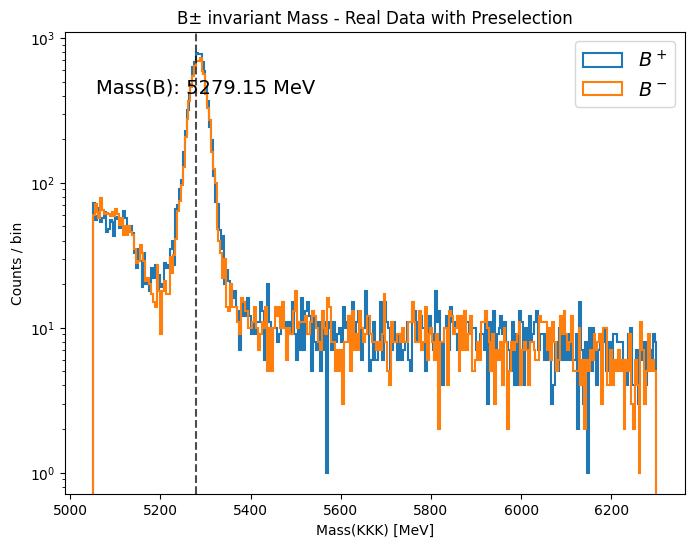

In [28]:
# Plot invariant mass for B+ and B-

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
for charge in [+1, -1]:
    maskPN = (data['B_Charge'] == charge)
    print(charge, len(data['B_Mass'][maskPN]))
    ax.hist(data['B_Mass'][maskPN], bins=300, histtype="step", linewidth=1.5, label=r'$B^+$' if charge==1 else r'$B^-$')
    
ax.axvline(5279.15, 0, 1, ls='--', alpha=0.7, color='k')
ax.set_yscale('log')
ax.set_title("B± invariant Mass - Real Data with Preselection")
ax.set_xlabel("Mass(KKK) [MeV]")
ax.set_ylabel("Counts / bin")
ax.text(0.05, 0.9, f"Mass(B): 5279.15 MeV", transform=ax.transAxes, fontsize=14, verticalalignment='top')
# ax.set_xlim(left=5100, right=5500)
ax.legend(fontsize=14)

In [29]:
# cut the data in the fit window --> 5150 MeV - 5450 MeV
FIT_WINDOW = [5100, 6000]

fit_window_mask = (data['B_Mass'] > FIT_WINDOW[0]) & (data['B_Mass'] < FIT_WINDOW[1])
data_window = data[fit_window_mask].reset_index(drop=True)

events in fit window [5100, 6000] MeV: 21454
  B+ : 11194   B- : 10260  -->  A_CP = -0.043535
  magnet down: 12702   magnet up: 8752


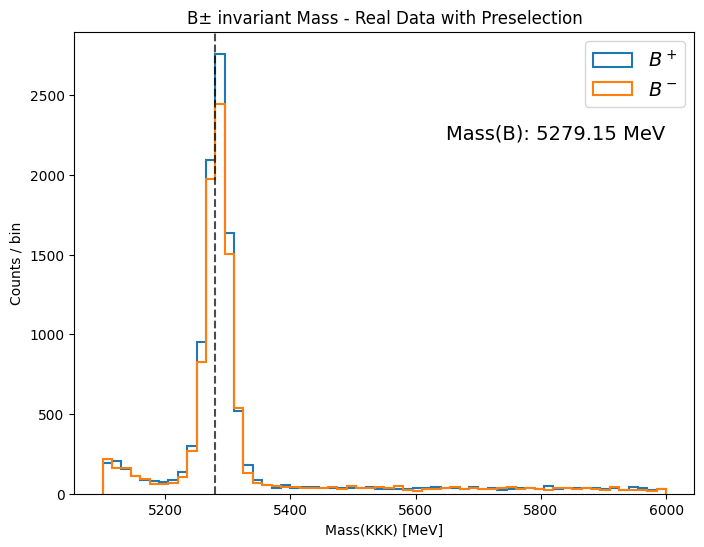

In [30]:
# Plot invariant mass for B+ and B-
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
bins = np.linspace(FIT_WINDOW[0], FIT_WINDOW[1], 61)
for charge in [+1, -1]:
    maskPN = (data_window['B_Charge'] == charge)
    ax.hist(data_window['B_Mass'][maskPN], bins=bins, histtype="step", linewidth=1.5, label=r'$B^+$' if charge==1 else r'$B^-$')
    
ax.axvline(5279.15, 0, 1, ls='--', alpha=0.7, color='k')
# ax.set_yscale('log')
ax.set_title("B± invariant Mass - Real Data with Preselection")
ax.set_xlabel("Mass(KKK) [MeV]")
ax.set_ylabel("Counts / bin")
ax.text(0.6, 0.8, f"Mass(B): 5279.15 MeV", transform=ax.transAxes, fontsize=14, verticalalignment='top')
# ax.set_xlim(left=5100, right=5500)
ax.legend(fontsize=14)

print(f"events in fit window [{FIT_WINDOW[0]}, {FIT_WINDOW[1]}] MeV: {len(data_window)}")
N_pos, N_neg = np.sum(data_window['B_Charge'] == 1), np.sum(data_window['B_Charge'] == -1)
print(f"  B+ : {N_pos}   B- : {N_neg}  -->  A_CP = {(N_neg - N_pos) / (N_pos + N_neg):.6f}")
print(f"  magnet down: {np.sum(data_window['magnet'] == 'down')}   magnet up: {np.sum(data_window['magnet'] == 'up')}")

## Frequentist fit

Events in sideband: 2432 (B+) / 2337 (B-)
Total events: 21454


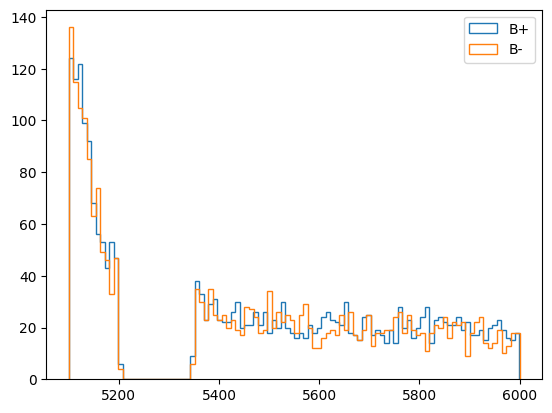

In [31]:
# Create Sideband Dataset
sig_min, sig_max = 5200, 5350

# signal mask: True if an event is in the signal region
in_signal = (data_window['B_Mass'] >= sig_min) & (data_window['B_Mass'] <= sig_max)

# Sideband data is everything NOT in the signal region
mask_pos = (data_window['B_Charge'] == 1)
data_sb_pos = data_window['B_Mass'][~in_signal & mask_pos]
data_sb_neg = data_window['B_Mass'][~in_signal & ~mask_pos]
N_sb_pos = len(data_sb_pos)
N_sb_neg = len(data_sb_neg)
print(f"Events in sideband: {N_sb_pos} (B+) / {N_sb_neg} (B-)")
print(f"Total events: {len(data_window)}")

plt.hist(data_sb_pos, bins=100, histtype='step', label='B+')
plt.hist(data_sb_neg, bins=100, histtype='step', label='B-')
plt.legend()
plt.show()

In [32]:
def pdf_sideband_2_expon(m, lam1, lam2, f_bkgs):
    """
    Miscela di due esponenziali con frazione f_bkgs di comp_1 e (1-f_bkgs) di comp_2.
    """
    int_left1 = (np.exp(-lam1 * FIT_WINDOW[0]) - np.exp(-lam1 * sig_min)) / lam1
    int_right1 = (np.exp(-lam1 * sig_max) - np.exp(-lam1 * FIT_WINDOW[1])) / lam1
    pdf1 = np.exp(-lam1 * m) / (int_left1 + int_right1)

    int_left2 = (np.exp(-lam2 * FIT_WINDOW[0]) - np.exp(-lam2 * sig_min)) / lam2
    int_right2 = (np.exp(-lam2 * sig_max) - np.exp(-lam2 * FIT_WINDOW[1])) / lam2
    pdf2 = np.exp(-lam2 * m) / (int_left2 + int_right2)

    return f_bkgs * pdf1 + (1 - f_bkgs) * pdf2

Sideband B+
lam1    -> 0.019396 ± 0.002456
lam2    -> 0.000497 ± 0.000143
f_bkgs  -> 0.239148 ± 0.016035
Sideband B-
lam1    -> 0.022449 ± 0.002532
lam2    -> 0.000703 ± 0.000140
f_bkgs  -> 0.230987 ± 0.015909


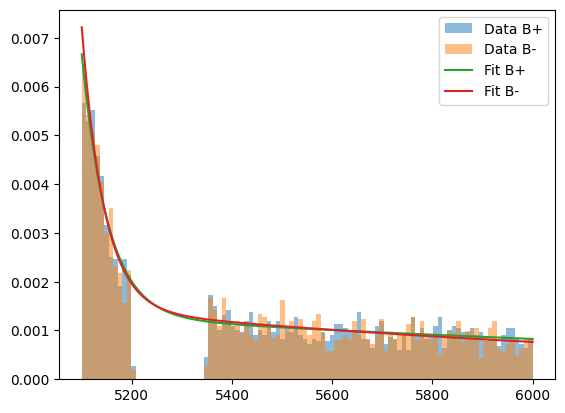

In [33]:
# Fit the sideband
print("Sideband B+")
nll_sb = UnbinnedNLL(data_sb_pos, pdf_sideband_2_expon)
m_fit_pos = Minuit(nll_sb, lam1=0.01, lam2=0.01, f_bkgs=0.5) # Initial guess for lambda
m_fit_pos.limits['lam1'] = (0.00001, 1.0) # Decay constant must be positive
m_fit_pos.limits['lam2'] = (0.00001, 1.0)
m_fit_pos.limits['f_bkgs'] = (0.0, 1.0) # Fraction must be between 0 and 1
m_fit_pos.migrad()
lam_hat1_pos = m_fit_pos.values['lam1']
lam_hat2_pos = m_fit_pos.values['lam2']
f_bkgs_hat_pos = m_fit_pos.values['f_bkgs']
for key, value, err in zip(m_fit_pos.parameters, m_fit_pos.values, m_fit_pos.errors):
    print(f"{key:7s} -> {value:.6f} ± {err:.6f}")

print("Sideband B-")
nll_sb = UnbinnedNLL(data_sb_neg, pdf_sideband_2_expon)
m_fit_neg = Minuit(nll_sb, lam1=0.01, lam2=0.01, f_bkgs=0.5) # Initial guess for lambda
m_fit_neg.limits['lam1'] = (0.00001, 1.0) # Decay constant must be positive
m_fit_neg.limits['lam2'] = (0.00001, 1.0)
m_fit_neg.limits['f_bkgs'] = (0.0, 1.0) # Fraction must be between 0 and 1
m_fit_neg.migrad()
lam_hat1_neg = m_fit_neg.values['lam1']
lam_hat2_neg = m_fit_neg.values['lam2']
f_bkgs_hat_neg = m_fit_neg.values['f_bkgs']
for key, value, err in zip(m_fit_neg.parameters, m_fit_neg.values, m_fit_neg.errors):
    print(f"{key:7s} -> {value:.6f} ± {err:.6f}")

# plot the histogram and the pdf on top
plt.hist(data_sb_pos, bins=100, range=FIT_WINDOW, density=True, alpha=0.5, label='Data B+')
plt.hist(data_sb_neg, bins=100, range=FIT_WINDOW, density=True, alpha=0.5, label='Data B-')

x = np.linspace(FIT_WINDOW[0], FIT_WINDOW[1], 1000)
plt.plot(x, pdf_sideband_2_expon(x, lam_hat1_pos, lam_hat2_pos, f_bkgs_hat_pos), label='Fit B+')
plt.plot(x, pdf_sideband_2_expon(x, lam_hat1_neg, lam_hat2_neg, f_bkgs_hat_neg), label='Fit B-')

plt.legend()
plt.show()

In [34]:
# Calculate expected background (b) in the signal region
# We need the integral of the unnormalized exponential over the signal region
int_signal = (np.exp(-lam_hat1_pos * sig_min) - np.exp(-lam_hat1_pos * sig_max)) / lam_hat1_pos + (np.exp(-lam_hat2_pos * sig_min) - np.exp(-lam_hat2_pos * sig_max)) / lam_hat2_pos
int_left = (np.exp(-lam_hat1_pos * FIT_WINDOW[0]) - np.exp(-lam_hat1_pos * sig_min)) / lam_hat1_pos + (np.exp(-lam_hat2_pos * FIT_WINDOW[0]) - np.exp(-lam_hat2_pos * sig_min)) / lam_hat2_pos
int_right = (np.exp(-lam_hat1_pos * sig_max) - np.exp(-lam_hat1_pos * FIT_WINDOW[1])) / lam_hat1_pos + (np.exp(-lam_hat2_pos * sig_max) - np.exp(-lam_hat2_pos * FIT_WINDOW[1])) / lam_hat2_pos

# b = (Total sideband events) * (Ratio of probability areas)
expected_b = N_sb_pos * (int_signal / (int_left + int_right))
print(f"Expected background in signal region (b) for B+: {expected_b:.1f}")

# Count actual observed events in the signal window
N_obs = np.sum(in_signal[mask_pos])
print(f"Observed events in signal region (N_obs) for B+: {N_obs}")


int_signal = (np.exp(-lam_hat1_neg * sig_min) - np.exp(-lam_hat1_neg * sig_max)) / lam_hat1_neg + (np.exp(-lam_hat2_neg * sig_min) - np.exp(-lam_hat2_neg * sig_max)) / lam_hat2_neg
int_left = (np.exp(-lam_hat1_neg * FIT_WINDOW[0]) - np.exp(-lam_hat1_neg * sig_min)) / lam_hat1_neg + (np.exp(-lam_hat2_neg * FIT_WINDOW[0]) - np.exp(-lam_hat2_neg * sig_min)) / lam_hat2_neg
int_right = (np.exp(-lam_hat1_neg * sig_max) - np.exp(-lam_hat1_neg * FIT_WINDOW[1])) / lam_hat1_neg + (np.exp(-lam_hat2_neg * sig_max) - np.exp(-lam_hat2_neg * FIT_WINDOW[1])) / lam_hat2_neg

expected_b = N_sb_neg * (int_signal / (int_left + int_right))
print(f"\nExpected background in signal region (b) for B-: {expected_b:.1f}")

N_obs = np.sum(in_signal[~mask_pos])
print(f"Observed events in signal region (N_obs) for B-: {N_obs}")

Expected background in signal region (b) for B+: 568.7
Observed events in signal region (N_obs) for B+: 8762

Expected background in signal region (b) for B-: 580.4
Observed events in signal region (N_obs) for B-: 7923


In [35]:
def pdf_composite(m, f_sig, mu, sigma, lam1, lam2, f_bkgs):
    """
    Composite PDF: (1 - f_sig) * Background + f_sig * Signal
    Both components must be individually normalized over the range!
    """
    
    # Background Component (Double Exponential)
    int_bkg1 = (np.exp(-lam1 * FIT_WINDOW[0]) - np.exp(-lam1 * FIT_WINDOW[1])) / lam1
    pdf1 = np.exp(-lam1 * m) / int_bkg1

    int_bkg2 = (np.exp(-lam2 * FIT_WINDOW[0]) - np.exp(-lam2 * FIT_WINDOW[1])) / lam2
    pdf2 = np.exp(-lam2 * m) / int_bkg2
    
    pdf_bkg = f_bkgs * pdf1 + (1 - f_bkgs) * pdf2

    # Signal Component (Gaussian)
    sig_norm = norm.cdf(FIT_WINDOW[1], loc=mu, scale=sigma) - norm.cdf(FIT_WINDOW[0], loc=mu, scale=sigma)
    pdf_sig = norm.pdf(m, loc=mu, scale=sigma) / sig_norm

    return (1.0 - f_sig) * pdf_bkg + f_sig * pdf_sig

In [36]:
# Fit with all the data in the window --> B+
nll_comp_pos = UnbinnedNLL(data_window['B_Mass'][mask_pos], pdf_composite)
m_comp_pos = Minuit(nll_comp_pos, f_sig=0.91, mu=5279.15, sigma=50, lam1=lam_hat1_pos, lam2=lam_hat2_pos, f_bkgs=f_bkgs_hat_pos)

m_comp_pos.limits['f_sig'] = (0.0, 1.0)        # Fraction must be between 0 and 100%
m_comp_pos.limits['mu'] = (sig_min, sig_max)   # We expect the mass to be in this window
m_comp_pos.limits['sigma'] = (0.0, 100.0)      # Width must be positive
m_comp_pos.limits['lam1'] = (1e-6, 1.0)      # Decay constant must be positive
m_comp_pos.limits['lam2'] = (1e-6, 1.0)      # Decay constant must be positive
m_comp_pos.limits['f_bkgs'] = (0.0, 1.0)       # Fraction must be between 0 and 100%

m_comp_pos.migrad()
m_comp_pos.hesse()
m_comp_pos.minos()

display(m_comp_pos)

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 1.213e+05                  │             Nfcn = 1147              │
│ EDM = 4.4e-05 (Goal: 0.0002)     │            time = 1.2 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ f_sig  │   0.721   │   0.005   │   -0.006   │   0.005    │    0    │    1    │       │
│ 1 │ mu     │ 5.28433e3 │ 0.00022e3 │ -0.00022e3 │ 0.00022e3  │  5200   │  5350   │       │
│ 2 │ sigma  │   18.18   │   0.21    │   -0.21    │    0.21    │    0    │   100   │       │
│ 3 │ lam1   │  0.0120   │  0.0025   │  -0.0023   │   0.0027   │  1e-06  │    1    │       │
│ 4 │ lam2   │  0.43e-3  │  0.24e-3  │  -0.27e-3  │  0.22e-3   │  1e-06  │    1    │       │
│ 5 │ f_bkgs │   0.29    │   0.05    │   -0.04    │    0.06    │    0    │    1    │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         f_sig         │          mu           │         sigma         │         lam1          │         lam2          │        f_bkgs         │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │  -0.006   │   0.005   │   -0.22   │   0.22    │   -0.21   │   0.21    │  -0.0023  │  0.0027   │ -0.27e-3  │  0.22e-3  │   -0.04   │   0.06    │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ Max FCN  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ New Min  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
└──────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┘
┌────────┬─────────────────────────────────────────────────────────────┐
│        │     f_sig        mu     sigma      lam1      lam2    f_bkgs │
├────────┼─────────────────────────────────────────────────────────────┤
│  f_sig │     3e-05 -0.097e-3  0.429e-3      6e-6   0.31e-6 -0.098e-3 │
│     mu │ -0.097e-3    0.0499     -0.00    -81e-6  -6.52e-6    0.0016 │
│  sigma │  0.429e-3     -0.00    0.0429    214e-6  10.64e-6   -0.0034 │
│   lam1 │      6e-6    -81e-6    214e-6  6.42e-06   0.49e-6   -116e-6 │
│   lam2 │   0.31e-6  -6.52e-6  10.64e-6   0.49e-6  5.73e-08 -10.56e-6 │
│ f_bkgs │ -0.098e-3    0.0016   -0.0034   -116e-6 -10.56e-6    0.0024 │
└────────┴─────────────────────────────────────────────────────────────┘

In [37]:
# Fit with all the data in the window --> B-
nll_comp_neg = UnbinnedNLL(data_window['B_Mass'][~mask_pos], pdf_composite)
m_comp_neg = Minuit(nll_comp_neg, f_sig=0.91, mu=5279.15, sigma=50, lam1=lam_hat1_neg, lam2=lam_hat2_neg, f_bkgs=f_bkgs_hat_neg)

m_comp_neg.limits['f_sig'] = (0.0, 1.0)        # Fraction must be between 0 and 100%
m_comp_neg.limits['mu'] = (sig_min, sig_max)   # We expect the mass to be in this window
m_comp_neg.limits['sigma'] = (0.0, 100.0)      # Width must be positive
m_comp_neg.limits['lam1'] = (0.0001, 1.0)      # Decay constant must be positive
m_comp_neg.limits['lam2'] = (0.0001, 1.0)      # Decay constant must be positive
m_comp_neg.limits['f_bkgs'] = (0.0, 1.0)       # Fraction must be between 0 and 100%

m_comp_neg.migrad()
m_comp_neg.hesse()
m_comp_neg.minos()

display(m_comp_neg)

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 1.115e+05                  │              Nfcn = 775              │
│ EDM = 1.01e-05 (Goal: 0.0002)    │            time = 0.8 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ f_sig  │   0.718   │   0.005   │   -0.005   │   0.005    │    0    │    1    │       │
│ 1 │ mu     │ 5.28446e3 │ 0.00023e3 │ -0.00023e3 │ 0.00023e3  │  5200   │  5350   │       │
│ 2 │ sigma  │   18.12   │   0.19    │   -0.19    │    0.19    │    0    │   100   │       │
│ 3 │ lam1   │  0.0219   │  0.0027   │  -0.0026   │   0.0028   │ 0.0001  │    1    │       │
│ 4 │ lam2   │  0.81e-3  │  0.14e-3  │  -0.14e-3  │  0.14e-3   │ 0.0001  │    1    │       │
│ 5 │ f_bkgs │   0.203   │   0.020   │   -0.019   │   0.020    │    0    │    1    │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         f_sig         │          mu           │         sigma         │         lam1          │         lam2          │        f_bkgs         │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │  -0.005   │   0.005   │   -0.23   │   0.23    │   -0.19   │   0.19    │  -0.0026  │  0.0028   │ -0.14e-3  │  0.14e-3  │  -0.019   │   0.020   │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ Max FCN  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ New Min  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
└──────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┘
┌────────┬─────────────────────────────────────────────────────────────┐
│        │     f_sig        mu     sigma      lam1      lam2    f_bkgs │
├────────┼─────────────────────────────────────────────────────────────┤
│  f_sig │  2.65e-05 -0.023e-3  0.234e-3      0e-6 -0.163e-6  0.014e-3 │
│     mu │ -0.023e-3    0.0526     -0.00    -56e-6 -0.956e-6    0.3e-3 │
│  sigma │  0.234e-3     -0.00    0.0371     22e-6 -5.178e-6    0.4e-3 │
│   lam1 │      0e-6    -56e-6     22e-6  7.12e-06  0.193e-6    -37e-6 │
│   lam2 │ -0.163e-6 -0.956e-6 -5.178e-6  0.193e-6  2.01e-08 -2.037e-6 │
│ f_bkgs │  0.014e-3    0.3e-3    0.4e-3    -37e-6 -2.037e-6  0.000387 │
└────────┴─────────────────────────────────────────────────────────────┘

In [38]:
# Compute asymmetry from the fit results
N_sig_pos = m_comp_pos.values['f_sig'] * len(data_window['B_Mass'][mask_pos])
N_sig_neg = m_comp_neg.values['f_sig'] * len(data_window['B_Mass'][~mask_pos])

A_CP = (N_sig_neg - N_sig_pos) / (N_sig_pos + N_sig_neg)
print(f"Number of signal events B+: {N_sig_pos:.1f}")
print(f"Number of signal events B-: {N_sig_neg:.1f}")
print(f"Asymmetry: {A_CP:.6f}")

Number of signal events B+: 8065.4
Number of signal events B-: 7364.9
Asymmetry: -0.045402


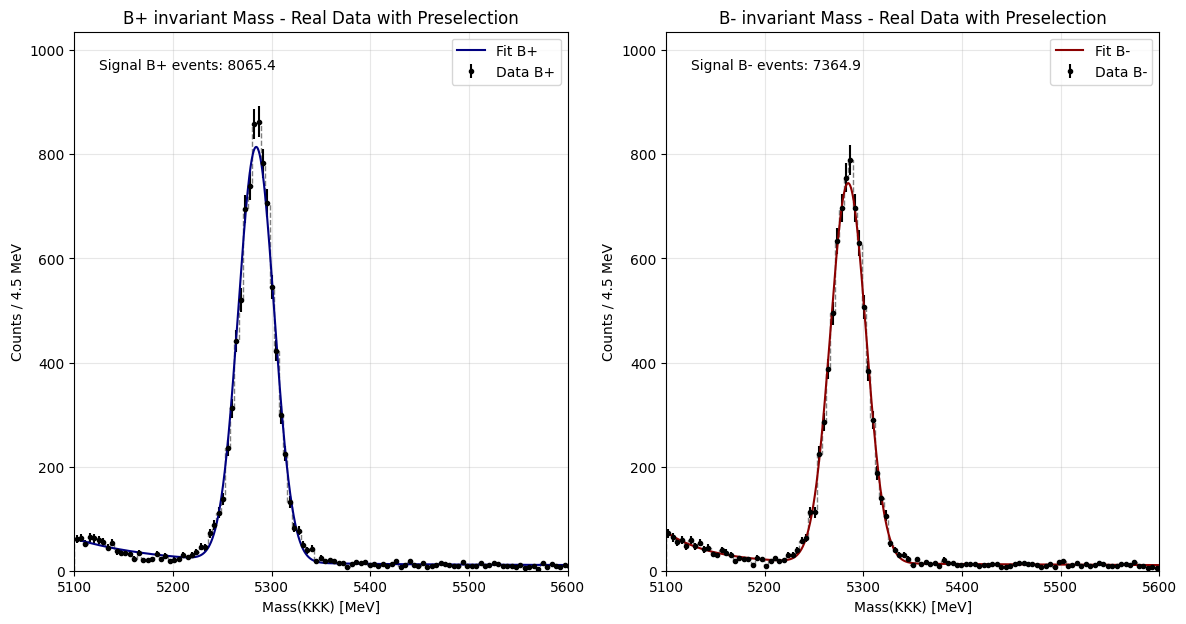

In [39]:
# plot the histogram and the pdf on top
bin_number = 200
bin_content_pos, x = np.histogram(data_window['B_Mass'][mask_pos], bins=bin_number, range=FIT_WINDOW)
bin_size = x[1] - x[0]
bin_centre = (x[:-1] + x[1:]) / 2
N_tot_pos = sum(bin_content_pos)

bin_content_neg, x = np.histogram(data_window['B_Mass'][~mask_pos], bins=bin_number, range=FIT_WINDOW)
bin_size = x[1] - x[0]
N_tot_neg = sum(bin_content_neg)


fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].hist(data_window['B_Mass'][mask_pos],  bins=bin_number, range=FIT_WINDOW, density=False, histtype='step', linestyle='--', alpha=0.5, color='k')
axes[0].errorbar(bin_centre, bin_content_pos, yerr=np.sqrt(bin_content_pos), marker='.', linestyle='None', color='k', label='Data B+')
axes[1].hist(data_window['B_Mass'][~mask_pos], bins=bin_number, range=FIT_WINDOW, density=False, histtype='step', linestyle='--', alpha=0.5, color='k')
axes[1].errorbar(bin_centre, bin_content_neg, yerr=np.sqrt(bin_content_neg), marker='.', linestyle='None', color='k', label='Data B-')

x = np.linspace(FIT_WINDOW[0], FIT_WINDOW[1], 10000)
axes[0].plot(x, N_tot_pos * bin_size * pdf_composite(x, m_comp_pos.values['f_sig'], m_comp_pos.values['mu'], m_comp_pos.values['sigma'], m_comp_pos.values['lam1'], m_comp_pos.values['lam2'], m_comp_pos.values['f_bkgs']), label='Fit B+', color='navy')
axes[1].plot(x, N_tot_neg * bin_size * pdf_composite(x, m_comp_neg.values['f_sig'], m_comp_neg.values['mu'], m_comp_neg.values['sigma'], m_comp_neg.values['lam1'], m_comp_neg.values['lam2'], m_comp_neg.values['f_bkgs']), label='Fit B-', color='darkred')
# plt.yscale('log')
axes[0].set_xlim(5100, 5600)
axes[1].set_xlim(5100, 5600)
axes[0].set_ylim(0, max(bin_content_pos)*1.2)
axes[1].set_ylim(0, max(bin_content_pos)*1.2)
axes[0].legend()
axes[1].legend()
axes[0].set_title("B+ invariant Mass - Real Data with Preselection")
axes[1].set_title("B- invariant Mass - Real Data with Preselection")
axes[0].set_ylabel(f"Counts / {bin_size:.1f} MeV")
axes[0].set_xlabel("Mass(KKK) [MeV]")
axes[1].set_ylabel(f"Counts / {bin_size:.1f} MeV")
axes[1].set_xlabel("Mass(KKK) [MeV]")
axes[0].grid(alpha=0.3)
axes[1].grid(alpha=0.3)
axes[0].text(0.05, 0.95, f"Signal B+ events: {N_sig_pos:.1f}", transform=axes[0].transAxes, verticalalignment='top')
axes[1].text(0.05, 0.95, f"Signal B- events: {N_sig_neg:.1f}", transform=axes[1].transAxes, verticalalignment='top')
plt.show()

#### Chi2???

In [40]:
def evaluate_chi_2(data, model, params, fit_window, bins):
    # 1. Istogramma i dati osservati (O_i)
    counts, bin_edges = np.histogram(data, bins=bins, range=fit_window)
    bin_width = bin_edges[1] - bin_edges[0]
    bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

    n_tot = len(data)
    expected = n_tot * bin_width * model(bin_centers, *params)

    # 3. Considera solo i bin con E_i > 0 per evitare divisioni per zero
    valid = expected > 0
    chi2_val = np.sum((counts[valid] - expected[valid])**2 / expected[valid])

    # 4. Gradi di libertà = numero di bin validi - numero di parametri liberi
    n_params = len(params)
    ndof = np.sum(valid) - n_params
    chi2_red = chi2_val / ndof
    p_value = chi2.sf(chi2_val, ndof)

    return chi2_val, ndof, chi2_red, p_value

In [41]:
chi2_val, ndof, chi2_red, p_value = evaluate_chi_2(data_window['B_Mass'][mask_pos],  pdf_composite, [m_comp_pos.values['f_sig'], m_comp_pos.values['mu'], m_comp_pos.values['sigma'], m_comp_pos.values['lam1'], m_comp_pos.values['lam2'], m_comp_pos.values['f_bkgs']], FIT_WINDOW, bins=200)
print(f"Chi2:         {chi2_val:.2f}")
print(f"NDOF:         {ndof}")
print(f"Chi2 / NDOF:  {chi2_red:.3f}")
print(f"p-value:      {p_value:.4f}\n")

chi2_val, ndof, chi2_red, p_value = evaluate_chi_2(data_window['B_Mass'][~mask_pos], pdf_composite, [m_comp_neg.values['f_sig'], m_comp_neg.values['mu'], m_comp_neg.values['sigma'], m_comp_neg.values['lam1'], m_comp_neg.values['lam2'], m_comp_neg.values['f_bkgs']], FIT_WINDOW, bins=200)
print(f"Chi2:         {chi2_val:.2f}")
print(f"NDOF:         {ndof}")
print(f"Chi2 / NDOF:  {chi2_red:.3f}")
print(f"p-value:      {p_value:.4f}\n")

Chi2:         263.04
NDOF:         194
Chi2 / NDOF:  1.356
p-value:      0.0007

Chi2:         200.27
NDOF:         194
Chi2 / NDOF:  1.032
p-value:      0.3637



In [42]:
bins = np.logspace(0, 5, num=50, base=5)
print(bins)

[1.00000000e+00 1.17848340e+00 1.38882313e+00 1.63670500e+00
 1.92882968e+00 2.27309376e+00 2.67880326e+00 3.15692518e+00
 3.72038392e+00 4.38441070e+00 5.16695523e+00 6.08917097e+00
 7.17598691e+00 8.45678146e+00 9.96617658e+00 1.17449737e+01
 1.38412565e+01 1.63116910e+01 1.92230571e+01 2.26540538e+01
 2.66974263e+01 3.14624738e+01 3.70780031e+01 4.36958112e+01
 5.14947882e+01 6.06857531e+01 7.15171527e+01 8.42817773e+01
 9.93246756e+01 1.17052481e+02 1.37944406e+02 1.62565193e+02
 1.91580382e+02 2.25774300e+02 2.66071265e+02 3.13560569e+02
 3.69525926e+02 4.35480170e+02 5.13206152e+02 6.04804931e+02
 7.12752572e+02 8.39967075e+02 9.89887255e+02 1.16656570e+03
 1.37477831e+03 1.62015342e+03 1.90932391e+03 2.25010654e+03
 2.65171321e+03 3.12500000e+03]


In [43]:
bins = np.logspace(0, 3.5, num=100, base=5)
p_values = []
chi2s = []
for bin in bins:
    chi2_val, ndof, chi2_red, p_value = evaluate_chi_2(data_window['B_Mass'][mask_pos], pdf_composite, [m_comp_pos.values['f_sig'], m_comp_pos.values['mu'], m_comp_pos.values['sigma'], m_comp_pos.values['lam1'], m_comp_pos.values['lam2'], m_comp_pos.values['f_bkgs']], FIT_WINDOW, bins=int(bin))
    p_values.append(p_value)
    chi2s.append(chi2_red)

C:\Users\marco\AppData\Local\Temp\ipykernel_11436\869354833.py:17: RuntimeWarning: divide by zero encountered in scalar divide
  chi2_red = chi2_val / ndof


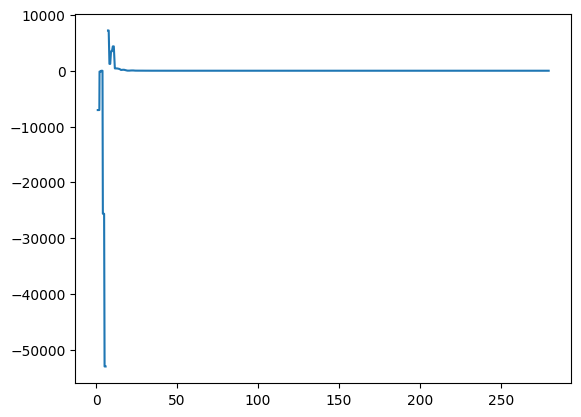

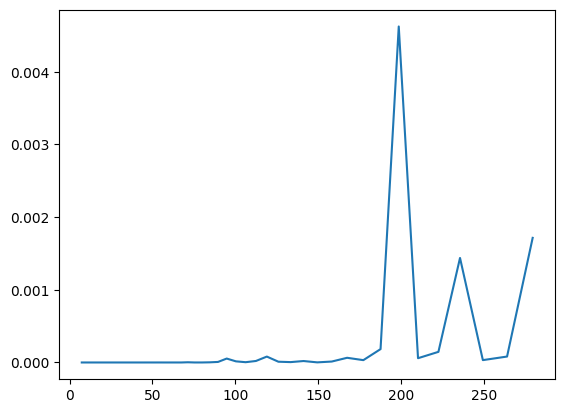

In [44]:
plt.plot(bins, chi2s)
plt.show()
plt.plot(bins, p_values)
plt.show()

### Joint Fit

I want to do a joint fot for the B+ and B- peaks. 

The common parameters are:

- mu:    B+/B- mass, the same = 5279.15 MeV
- sigma: resolution, the same for B+/B- because the detector is symmetric
- N_sig: signal events (B+ and B-)
- A_CP:  CP asymmetry (N_sig_neg - N_sig_pos) / (N_sig_neg + N_sig_pos)

Specific parameters:

- For B+
    - N_bkg_pos:  events of bkgs
    - lam1_pos:   bkg1
    - lam2_pos:   bkg2
    - f_bkgs_pos: fraction of contribution bkg1 respect bkg2

- For B-
    - N_bkg_neg:  events of bkgs
    - lam1_neg:   bkg1
    - lam2_neg:   bkg2
    - f_bkgs_neg: fraction of contribution bkg1 respect bkg2

In [45]:
lo, hi = FIT_WINDOW
m_pos = data_window['B_Mass'][mask_pos].to_numpy()
m_neg = data_window['B_Mass'][~mask_pos].to_numpy()

def density(m, N_sig, N_bkg, mu, sigma, lam1, lam2, f_bkgs):
    # normalized signal (Gaussian truncated to the window)
    sig = norm.pdf(m, mu, sigma) / (norm.cdf(hi, mu, sigma) - norm.cdf(lo, mu, sigma))
    # normalized double-exponential background
    e1 = np.exp(-lam1 * m) * lam1 / (np.exp(-lam1 * lo) - np.exp(-lam1 * hi))
    e2 = np.exp(-lam2 * m) * lam2 / (np.exp(-lam2 * lo) - np.exp(-lam2 * hi))
    bkg = f_bkgs * e1 + (1 - f_bkgs) * e2
    
    return N_sig * sig + N_bkg * bkg

# N_sig_pos = N_sig*(1-A)/2, N_sig_neg = N_sig*(1+A)/2
def model_pos(m, N_sig, A_CP, mu, sigma, N_bkg_pos, lam1_pos, lam2_pos, f_bkgs_pos):
    Ns = N_sig * (1 - A_CP) / 2
    return Ns + N_bkg_pos, density(m, Ns, N_bkg_pos, mu, sigma, lam1_pos, lam2_pos, f_bkgs_pos)

def model_neg(m, N_sig, A_CP, mu, sigma, N_bkg_neg, lam1_neg, lam2_neg, f_bkgs_neg):
    Ns = N_sig * (1 + A_CP) / 2
    return Ns + N_bkg_neg, density(m, Ns, N_bkg_neg, mu, sigma, lam1_neg, lam2_neg, f_bkgs_neg)

cost = ExtendedUnbinnedNLL(m_pos, model_pos) + ExtendedUnbinnedNLL(m_neg, model_neg)

m_joint = Minuit(cost,
    A_CP=0.0, mu=5279.15, N_sig=15000, sigma=20,
    N_bkg_pos=3100, N_bkg_neg=2900,
    lam1_pos=lam_hat1_pos, lam2_pos=lam_hat2_pos, f_bkgs_pos=f_bkgs_hat_pos,
    lam1_neg=lam_hat1_neg, lam2_neg=lam_hat2_neg, f_bkgs_neg=f_bkgs_hat_neg)

m_joint.limits['mu'] = (sig_min, sig_max)
m_joint.limits['sigma'] = (1, 100)
m_joint.limits['N_sig'] = (0, None)
m_joint.limits['A_CP'] = (-1.0, 1.0)

m_joint.limits[f'N_bkg_pos'] = (0, None)
# m_joint.limits[f'lam1_pos'] = (0.9 * lam_hat1_pos, 1.1 * lam_hat1_pos)
# m_joint.limits[f'lam2_pos'] = (0.9 * lam_hat2_pos, 1.1 * lam_hat2_pos)
# m_joint.limits[f'f_bkgs_pos'] = (0.9 * f_bkgs_hat_pos, 1.1 * f_bkgs_hat_pos)

m_joint.limits[f'N_bkg_neg'] = (0, None)
# m_joint.limits[f'lam1_neg'] = (0.9 * lam_hat1_neg, 1.1 * lam_hat1_neg)
# m_joint.limits[f'lam2_neg'] = (0.9 * lam_hat2_neg, 1.1 * lam_hat2_neg)
# m_joint.limits[f'f_bkgs_neg'] = (0.9 * f_bkgs_hat_neg, 1.1 * f_bkgs_hat_neg)

for s in ('pos', 'neg'):
    m_joint.limits[f'lam1_{s}'] = (1e-6, 1)
    m_joint.limits[f'lam2_{s}'] = (1e-6, 1)
    m_joint.limits[f'f_bkgs_{s}'] = (0, 1)

m_joint.migrad()
m_joint.hesse()
m_joint.minos()
# display(m_joint)

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -1.225e+05                 │             Nfcn = 3126              │
│ EDM = 3.69e-05 (Goal: 0.0002)    │            time = 6.0 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name       │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig      │  15.43e3  │  0.13e3   │  -0.13e3   │   0.13e3   │    0    │         │       │
│ 1 │ A_CP       │  -0.045   │   0.008   │   -0.008   │   0.008    │   -1    │    1    │       │
│ 2 │ mu         │ 5.28440e3 │ 0.00016e3 │ -0.00016e3 │ 0.00016e3  │  5200   │  5350   │       │
│ 3 │ sigma      │   18.15   │   0.14    │   -0.14    │    0.14    │    1    │   100   │       │
│ 4 │ N_bkg_pos  │  3.13e3   │  0.07e3   │  -0.07e3   │   0.07e3   │    0    │         │       │
│ 5 │ lam1_pos   │  0.0118   │  0.0026   │  -0.0021   │   0.0026   │  1e-06  │    1    │       │
│ 6 │ lam2_pos   │  0.42e-3  │  0.26e-3  │  -0.26e-3  │  0.22e-3   │  1e-06  │    1    │       │
│ 7 │ f_bkgs_pos │   0.29    │   0.05    │   -0.04    │    0.05    │    0    │    1    │       │
│ 8 │ N_bkg_neg  │  2.89e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 9 │ lam1_neg   │  0.0220   │  0.0027   │  -0.0025   │   0.0028   │  1e-06  │    1    │       │
│ 10│ lam2_neg   │  0.81e-3  │  0.14e-3  │  -0.14e-3  │  0.14e-3   │  1e-06  │    1    │       │
│ 11│ f_bkgs_neg │   0.203   │   0.020   │   -0.019   │   0.020    │    0    │    1    │       │
└───┴────────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │       lam1_pos        │       lam2_pos        │      f_bkgs_pos       │       N_bkg_neg       │       lam1_neg        │       lam2_neg        │      f_bkgs_neg       │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │  -0.13e3  │  0.13e3   │  -0.008   │   0.008   │   -0.16   │   0.16    │   -0.14   │   0.14    │    -70    │    70     │  -0.0021  │  0.0026   │ -0.26e-3  │  0.22e-3  │   -0.04   │   0.05    │    -60    │    60     │  -0.0025  │  0.0028   │ -0.14e-3  │  0.14e-3  │  -0.019   │   0.020   │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   Fals

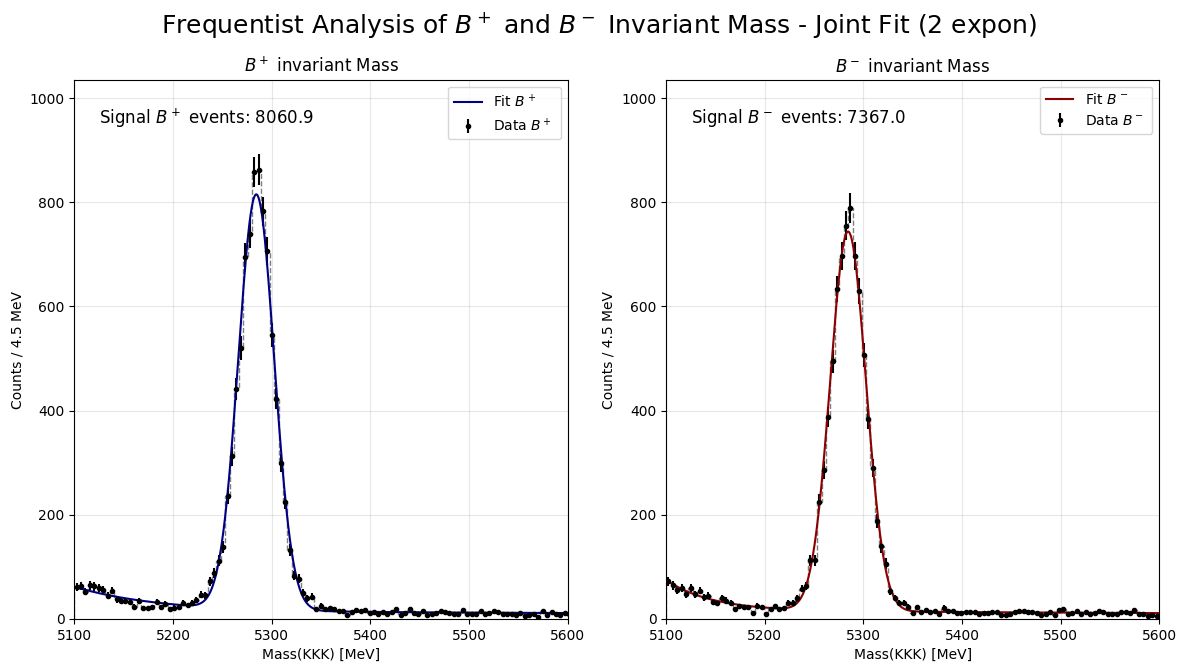

In [46]:
# plot the histogram and the pdf on top
bin_number = 200
bin_content_pos, x = np.histogram(data_window['B_Mass'][mask_pos], bins=bin_number, range=FIT_WINDOW)
bin_size = x[1] - x[0]
bin_centre = (x[:-1] + x[1:]) / 2
N_tot_pos = sum(bin_content_pos)

bin_content_neg, x = np.histogram(data_window['B_Mass'][~mask_pos], bins=bin_number, range=FIT_WINDOW)
bin_size = x[1] - x[0]
N_tot_neg = sum(bin_content_neg)


fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].hist(data_window['B_Mass'][mask_pos],  bins=bin_number, range=FIT_WINDOW, density=False, histtype='step', linestyle='--', alpha=0.5, color='k')
axes[0].errorbar(bin_centre, bin_content_pos, yerr=np.sqrt(bin_content_pos), marker='.', linestyle='None', color='k', label=r'Data $B^+$ ')
axes[1].hist(data_window['B_Mass'][~mask_pos], bins=bin_number, range=FIT_WINDOW, density=False, histtype='step', linestyle='--', alpha=0.5, color='k')
axes[1].errorbar(bin_centre, bin_content_neg, yerr=np.sqrt(bin_content_neg), marker='.', linestyle='None', color='k', label=r'Data $B^-$ ')

x = np.linspace(FIT_WINDOW[0], FIT_WINDOW[1], 10000)
axes[0].plot(x, bin_size * model_pos(x, m_joint.values['N_sig'], m_joint.values['A_CP'], m_joint.values['mu'], m_joint.values['sigma'], m_joint.values['N_bkg_pos'], m_joint.values['lam1_pos'], m_joint.values['lam2_pos'], m_joint.values['f_bkgs_pos'])[1], label=r'Fit $B^+$ ', color='navy')
axes[1].plot(x, bin_size * model_neg(x, m_joint.values['N_sig'], m_joint.values['A_CP'], m_joint.values['mu'], m_joint.values['sigma'], m_joint.values['N_bkg_neg'], m_joint.values['lam1_neg'], m_joint.values['lam2_neg'], m_joint.values['f_bkgs_neg'])[1], label=r'Fit $B^-$ ', color='darkred')
axes[0].set_xlim(5100, 5600)
axes[1].set_xlim(5100, 5600)
axes[0].set_ylim(0, max(bin_content_pos)*1.2)
axes[1].set_ylim(0, max(bin_content_pos)*1.2)
axes[0].legend()
axes[1].legend()
axes[0].set_title(r"$B^+$ invariant Mass")
axes[1].set_title(r"$B^-$ invariant Mass")
axes[0].set_ylabel(f"Counts / {bin_size:.1f} MeV")
axes[0].set_xlabel("Mass(KKK) [MeV]")
axes[1].set_ylabel(f"Counts / {bin_size:.1f} MeV")
axes[1].set_xlabel("Mass(KKK) [MeV]")
axes[0].grid(alpha=0.3)
axes[1].grid(alpha=0.3)
axes[0].text(0.05, 0.95, rf"Signal $B^+$ events: {m_joint.values['N_sig'] * (1 - m_joint.values['A_CP']) / 2:.1f}", transform=axes[0].transAxes, verticalalignment='top', fontsize=12)
axes[1].text(0.05, 0.95, rf"Signal $B^-$ events: {m_joint.values['N_sig'] * (1 + m_joint.values['A_CP']) / 2:.1f}", transform=axes[1].transAxes, verticalalignment='top', fontsize=12)
# axes[0].set_yscale('log')
# axes[1].set_yscale('log')
fig.suptitle(r"Frequentist Analysis of $B^+$ and $B^-$ Invariant Mass - Joint Fit (2 expon)", fontsize=18)
plt.show()

In [47]:
print(f"A_CP = {m_joint.values['A_CP']:.4f} ± {m_joint.errors['A_CP']:.4f}")
print(f"err  = {m_joint.errors['A_CP']/m_joint.values['A_CP']*100:.1f}%")
print(f"significance  = {abs(m_joint.values['A_CP']/m_joint.errors['A_CP']):.2f}")

A_CP = -0.0450 ± 0.0084
err  = -18.8%
significance  = 5.33


### Simpler Bkg Model

In [48]:
lo, hi = FIT_WINDOW
m_pos = data_window['B_Mass'][mask_pos].to_numpy()
m_neg = data_window['B_Mass'][~mask_pos].to_numpy()

def pdf_single_1(m, N_sig, N_bkg, mu, sigma, lam):
    # normalized signal (Gaussian truncated to the window)
    sig = norm.pdf(m, mu, sigma) / (norm.cdf(hi, mu, sigma) - norm.cdf(lo, mu, sigma))
    # normalized double-exponential background
    bkg = np.exp(-lam * m) * lam / (np.exp(-lam * lo) - np.exp(-lam * hi))
    return N_sig * sig + N_bkg * bkg

# N_sig_pos = N_sig*(1-A)/2, N_sig_neg = N_sig*(1+A)/2
def model_pos_1(m, N_sig, A_CP, mu, sigma, N_bkg_pos, lam_pos):
    Ns = N_sig * (1 - A_CP) / 2
    return Ns + N_bkg_pos, pdf_single_1(m, Ns, N_bkg_pos, mu, sigma, lam_pos)

def model_neg_1(m, N_sig, A_CP, mu, sigma, N_bkg_neg, lam_neg):
    Ns = N_sig * (1 + A_CP) / 2
    return Ns + N_bkg_neg, pdf_single_1(m, Ns, N_bkg_neg, mu, sigma, lam_neg)

cost_1 = ExtendedUnbinnedNLL(m_pos, model_pos_1) + ExtendedUnbinnedNLL(m_neg, model_neg_1)

m_joint_1 = Minuit(cost_1,
    N_sig=15000, A_CP=0.0, mu=5279.15, sigma=20,
    N_bkg_pos=3100, N_bkg_neg=2900,
    lam_pos=lam_hat1_pos,
    lam_neg=lam_hat1_neg)

m_joint_1.limits['mu'] = (sig_min, sig_max)
m_joint_1.limits['sigma'] = (1, 100)
m_joint_1.limits['N_sig'] = (0, None)
m_joint_1.limits['A_CP'] = (-1.0, 1.0)

m_joint_1.limits[f'N_bkg_pos'] = (0, None)
m_joint_1.limits[f'N_bkg_neg'] = (0, None)
m_joint_1.limits[f'lam_pos'] = (1e-6, 1)
m_joint_1.limits[f'lam_neg'] = (1e-6, 1)

m_joint_1.migrad()
m_joint_1.hesse()
m_joint_1.minos()
# display(m_joint_1)

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = -1.221e+05                 │              Nfcn = 829              │
│ EDM = 3.79e-06 (Goal: 0.0002)    │            time = 1.4 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name      │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼───────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ N_sig     │  15.03e3  │  0.13e3   │  -0.13e3   │   0.13e3   │    0    │         │       │
│ 1 │ A_CP      │  -0.048   │   0.008   │   -0.008   │   0.009    │   -1    │    1    │       │
│ 2 │ mu        │ 5.28439e3 │ 0.00016e3 │ -0.00016e3 │ 0.00016e3  │  5200   │  5350   │       │
│ 3 │ sigma     │   17.57   │   0.13    │   -0.13    │    0.13    │    1    │   100   │       │
│ 4 │ N_bkg_pos │  3.32e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 5 │ lam_pos   │  2.09e-3  │  0.08e-3  │  -0.08e-3  │  0.08e-3   │  1e-06  │    1    │       │
│ 6 │ N_bkg_neg │  3.10e3   │  0.06e3   │  -0.06e3   │   0.06e3   │    0    │         │       │
│ 7 │ lam_neg   │  2.11e-3  │  0.08e-3  │  -0.08e-3  │  0.08e-3   │  1e-06  │    1    │       │
└───┴───────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌──────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┬───────────────────────┐
│          │         N_sig         │         A_CP          │          mu           │         sigma         │       N_bkg_pos       │        lam_pos        │       N_bkg_neg       │        lam_neg        │
├──────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┼───────────┬───────────┤
│  Error   │  -0.13e3  │  0.13e3   │  -0.008   │   0.009   │   -0.16   │   0.16    │   -0.13   │   0.13    │    -60    │    60     │ -0.08e-3  │  0.08e-3  │    -60    │    60     │ -0.08e-3  │  0.08e-3  │
│  Valid   │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │   True    │
│ At Limit │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ Max FCN  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
│ New Min  │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │   False   │
└──────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┴───────────┘
┌───────────┬──────────────────────────────────────────────────────────────────────────────

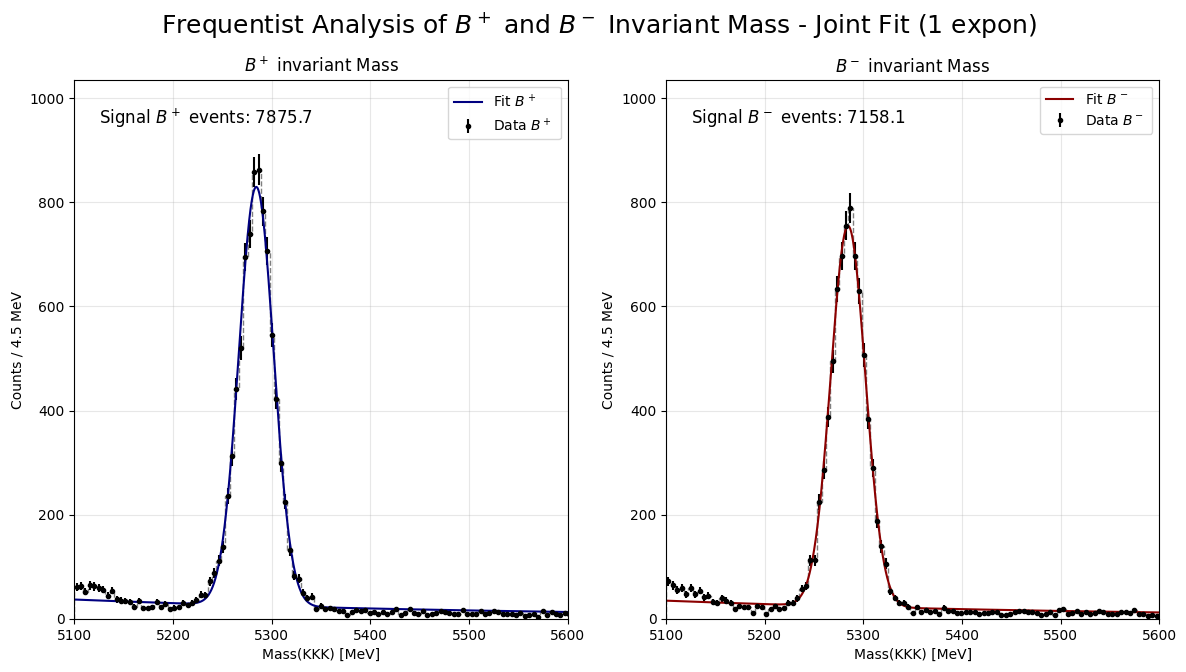

In [49]:
# plot the histogram and the pdf on top
bin_number = 200
bin_content_pos, x = np.histogram(data_window['B_Mass'][mask_pos], bins=bin_number, range=FIT_WINDOW)
bin_size = x[1] - x[0]
bin_centre = (x[:-1] + x[1:]) / 2
N_tot_pos = sum(bin_content_pos)

bin_content_neg, x = np.histogram(data_window['B_Mass'][~mask_pos], bins=bin_number, range=FIT_WINDOW)
bin_size = x[1] - x[0]
N_tot_neg = sum(bin_content_neg)


fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].hist(data_window['B_Mass'][mask_pos],  bins=bin_number, range=FIT_WINDOW, density=False, histtype='step', linestyle='--', alpha=0.5, color='k')
axes[0].errorbar(bin_centre, bin_content_pos, yerr=np.sqrt(bin_content_pos), marker='.', linestyle='None', color='k', label=r'Data $B^+$ ')
axes[1].hist(data_window['B_Mass'][~mask_pos], bins=bin_number, range=FIT_WINDOW, density=False, histtype='step', linestyle='--', alpha=0.5, color='k')
axes[1].errorbar(bin_centre, bin_content_neg, yerr=np.sqrt(bin_content_neg), marker='.', linestyle='None', color='k', label=r'Data $B^-$ ')

x = np.linspace(FIT_WINDOW[0], FIT_WINDOW[1], 10000)
axes[0].plot(x, bin_size * model_pos_1(x, m_joint_1.values['N_sig'], m_joint_1.values['A_CP'], m_joint_1.values['mu'], m_joint_1.values['sigma'], m_joint_1.values['N_bkg_pos'], m_joint_1.values['lam_pos'])[1], label=r'Fit $B^+$ ', color='navy')
axes[1].plot(x, bin_size * model_neg_1(x, m_joint_1.values['N_sig'], m_joint_1.values['A_CP'], m_joint_1.values['mu'], m_joint_1.values['sigma'], m_joint_1.values['N_bkg_neg'], m_joint_1.values['lam_neg'])[1], label=r'Fit $B^-$ ', color='darkred')
axes[0].set_xlim(5100, 5600)
axes[1].set_xlim(5100, 5600)
axes[0].set_ylim(0, max(bin_content_pos)*1.2)
axes[1].set_ylim(0, max(bin_content_pos)*1.2)
axes[0].legend()
axes[1].legend()
axes[0].set_title(r"$B^+$ invariant Mass")
axes[1].set_title(r"$B^-$ invariant Mass")
axes[0].set_ylabel(f"Counts / {bin_size:.1f} MeV")
axes[0].set_xlabel("Mass(KKK) [MeV]")
axes[1].set_ylabel(f"Counts / {bin_size:.1f} MeV")
axes[1].set_xlabel("Mass(KKK) [MeV]")
axes[0].grid(alpha=0.3)
axes[1].grid(alpha=0.3)
axes[0].text(0.05, 0.95, rf"Signal $B^+$ events: {m_joint_1.values['N_sig'] * (1 - m_joint_1.values['A_CP']) / 2:.1f}", transform=axes[0].transAxes, verticalalignment='top', fontsize=12)
axes[1].text(0.05, 0.95, rf"Signal $B^-$ events: {m_joint_1.values['N_sig'] * (1 + m_joint_1.values['A_CP']) / 2:.1f}", transform=axes[1].transAxes, verticalalignment='top', fontsize=12)
# axes[0].set_yscale('log')
# axes[1].set_yscale('log')
fig.suptitle(r"Frequentist Analysis of $B^+$ and $B^-$ Invariant Mass - Joint Fit (1 expon)", fontsize=18)
plt.show()

In [50]:
print(f"A_CP = {m_joint_1.values['A_CP']:.4f} ± {m_joint_1.errors['A_CP']:.4f}")
print(f"err  = {m_joint_1.errors['A_CP']/m_joint_1.values['A_CP']*100:.1f}%")
print(f"significance  = {abs(m_joint_1.values['A_CP']/m_joint_1.errors['A_CP']):.2f}")

A_CP = -0.0477 ± 0.0085
err  = -17.8%
significance  = 5.62


### Profiled Likelihood

In [51]:
parameters_of_interest = ['A_CP', 'mu']
nuisance_params        = ['N_sig', 'sigma', 'N_bkg_pos', 'lam1_pos', 'lam2_pos', 'f_bkgs_pos', 'N_bkg_pos', 'lam1_neg', 'lam2_neg', 'f_bkgs_neg']

Text(0, 0.5, '$2\\Delta\\, NLL$')

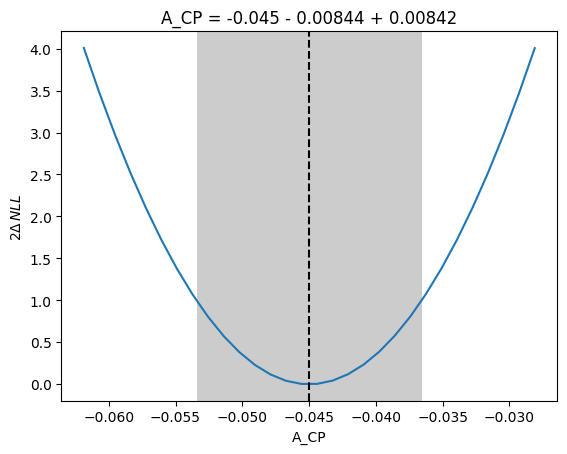

In [ ]:
m_joint.draw_mnprofile('A_CP');
plt.ylabel(r'$2\Delta\, NLL$');

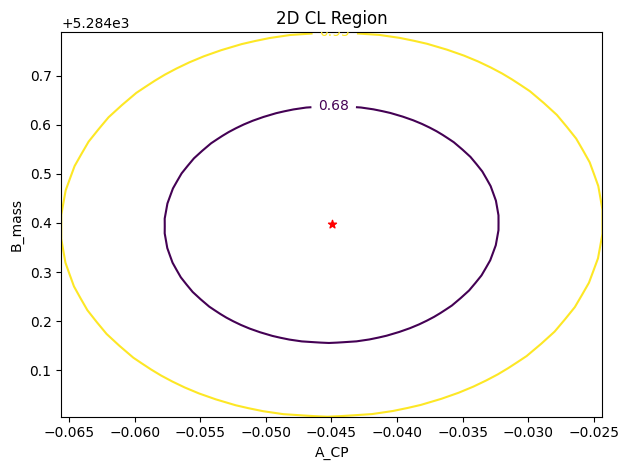

In [53]:
m_joint.draw_mncontour('A_CP', 'mu', cl=[0.68, 0.95]);
plt.scatter([m_joint.values['A_CP']], [m_joint.values['mu']], marker='*', color='r')
plt.title("2D CL Region")
plt.xlabel('A_CP')
plt.ylabel('B_mass')
plt.tight_layout()

In [54]:
def run_coverage_study(data, fit_window, N_toys=30):
    # Critical value for 68.3% coverage in ND (chi2 with df=2)
    t_critical_2D = chi2(2).ppf(0.6827)

    t_values = []
    A_CP_values = []
    covered_count = 0

    for i in tqdm(range(N_toys)):
        # Bootstrapping
        index_bootstrap = np.random.choice(data.index, size=len(data), replace=True)
        # Prepare data
        lo, hi = fit_window
        mask_pos = (data['B_Charge'][index_bootstrap] == 1)
        m_pos = data['B_Mass'][index_bootstrap][mask_pos].to_numpy()
        m_neg = data['B_Mass'][index_bootstrap][~mask_pos].to_numpy()
        
        
        cost = ExtendedUnbinnedNLL(m_pos, model_pos) + ExtendedUnbinnedNLL(m_neg, model_neg)
        
        # Unconstrained Fit (Global Minimum)
        m_joint_unconstrained = Minuit(cost,
            N_sig=15000, A_CP=m_joint.values['A_CP'], mu=m_joint.values['mu'], sigma=m_joint.values['sigma'],
            N_bkg_pos=3100, N_bkg_neg=2900,
            lam1_pos=lam_hat1_pos, lam2_pos=lam_hat2_pos, f_bkgs_pos=f_bkgs_hat_pos,
            lam1_neg=lam_hat1_neg, lam2_neg=lam_hat2_neg, f_bkgs_neg=f_bkgs_hat_neg)

        m_joint_unconstrained.limits['mu'] = (sig_min, sig_max)
        m_joint_unconstrained.limits['sigma'] = (1, 100)
        m_joint_unconstrained.limits['N_sig'] = (0, None)
        m_joint_unconstrained.limits['A_CP'] = (-1.0, 1.0)       
        for s in ('pos', 'neg'):
            m_joint_unconstrained.limits[f'N_bkg_{s}'] = (0, None)
            m_joint_unconstrained.limits[f'lam1_{s}'] = (1e-6, 1)
            m_joint_unconstrained.limits[f'lam2_{s}'] = (1e-6, 1)
            m_joint_unconstrained.limits[f'f_bkgs_{s}'] = (0, 1)
        
        
        m_joint_unconstrained.migrad()
        if not m_joint_unconstrained.valid:
            continue

        NLL_min = m_joint_unconstrained.fval
        A_CP_values.append(m_joint_unconstrained.values['A_CP'])
        
        
        # Constrained Fit (Fixing POIs to True Values)
        # We profile the nuisance parameters
        m_joint_constrained = Minuit(cost,
            N_sig=15000, A_CP=m_joint.values['A_CP'], mu=m_joint.values['mu'], sigma=m_joint.values['sigma'],
            N_bkg_pos=3100, N_bkg_neg=2900,
            lam1_pos=lam_hat1_pos, lam2_pos=lam_hat2_pos, f_bkgs_pos=f_bkgs_hat_pos,
            lam1_neg=lam_hat1_neg, lam2_neg=lam_hat2_neg, f_bkgs_neg=f_bkgs_hat_neg)
        
        m_joint_constrained.limits['sigma'] = (1, 100)
        m_joint_constrained.limits['N_sig'] = (0, None)
        for s in ('pos', 'neg'):
            m_joint_constrained.limits[f'N_bkg_{s}'] = (0, None)
            m_joint_constrained.limits[f'lam1_{s}'] = (1e-6, 1)
            m_joint_constrained.limits[f'lam2_{s}'] = (1e-6, 1)
            m_joint_constrained.limits[f'f_bkgs_{s}'] = (0, 1)

        # FIX the parameters of interest
        m_joint_constrained.fixed['A_CP'] = True
        m_joint_constrained.fixed['mu']   = True

        
        m_joint_constrained.migrad()
        NLL_true = m_joint_constrained.fval


        # Calculate Test Statistic
        t = (NLL_true - NLL_min)
        t = max(t, 0.0)
        t_values.append(t)

        # Check Coverage
        if t <= t_critical_2D:
            covered_count += 1

    del m_joint_constrained
    del m_joint_unconstrained
    
    coverage_fraction = covered_count / len(t_values)
    return np.array(t_values), coverage_fraction, A_CP_values

In [78]:
t_vals, cov, A_CP_values = run_coverage_study(data_window, FIT_WINDOW, N_toys=50)

  0%|          | 0/50 [00:00<?, ?it/s]

C:\Users\marco\AppData\Local\Temp\ipykernel_11436\3426538489.py:9: RuntimeWarning: invalid value encountered in divide
  e1 = np.exp(-lam1 * m) * lam1 / (np.exp(-lam1 * lo) - np.exp(-lam1 * hi))
C:\Users\marco\AppData\Local\Temp\ipykernel_11436\3426538489.py:10: RuntimeWarning: invalid value encountered in divide
  e2 = np.exp(-lam2 * m) * lam2 / (np.exp(-lam2 * lo) - np.exp(-lam2 * hi))


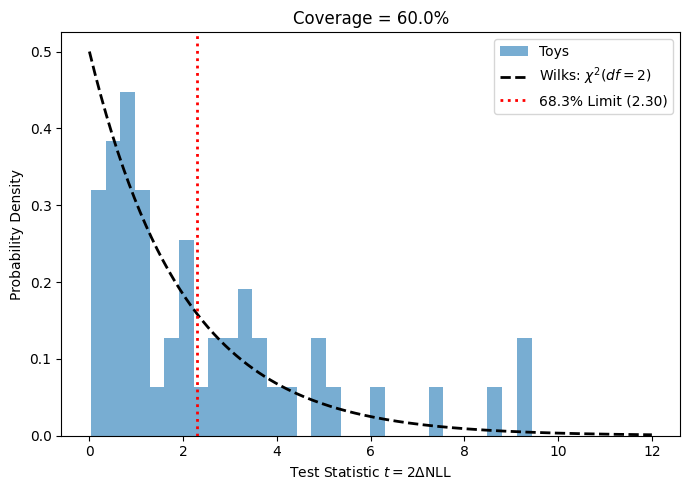

In [80]:
# Theoretical PDF for Wilks' theorem (chi-square with 2 degrees of freedom)
x_vals = np.linspace(0, 12, 200)
chi2_pdf = chi2(2).pdf(x_vals)

fig, ax = plt.subplots(1, 1, figsize=(7, 5))
ax.hist(t_vals, bins=30, density=True, alpha=0.6, label='Toys')
ax.plot(x_vals, chi2_pdf, 'k--', lw=2, label=r'Wilks: $\chi^2(df=2)$')
ax.axvline(chi2(2).ppf(0.6827), color='red', linestyle=':', lw=2, label='68.3% Limit (2.30)')
ax.set_title(f"Coverage = {cov*100:.1f}%")
ax.set_xlabel(r"Test Statistic $t = 2\Delta$NLL")
ax.set_ylabel("Probability Density")
ax.legend()

plt.tight_layout()
plt.show()

# Dalitz plots and two body resonances
## Aims:
* Produce Dalitz plots of the simulation and real data sample
* Create ordered and binned dalitz plots.
* Identify two body resonances in the Dalitz plots

In this stage we introduce you to an important technique for analysing decays of one particle (your charged B meson) into three bodies (the three kaons). This is known as a Dalitz plot. 

The decay of the B meson can proceed either directly to the three-body final state or via an intermediate particle. For example, B<sup>+</sup> → K<sup>+</sup>K<sup>+</sup>K<sup>−</sup>, could proceed through the decay  B<sup>+</sup> → K<sup>+</sup>R<sup>0</sup>, where R<sup>0</sup> is a neutral particle resonance which can decay R<sup>0</sup> → K<sup>+</sup>K<sup>-</sup>. Dalitz plots can be used to identify these resonances which are visible as bands on the Dalitz plot.

More information about these plots and why these are used in particle physics research can be found in [Dalitz Plot Introduction](Background-Information-Notebooks/DalitzPlots.ipynb).

The kinematics of a three-body decay can be fully described using only two variables. The energies and momenta of the three kaons are not independent of each other as they all come from the decay of a B meson and energy and momentum are conserved. The axes of the plots conventionally are the squared invariant masses of two pairs of the decay products. It is a 2D plot, the x and y axes are both squared masses and the density of points in the plot shows the structure.

Consider our decay B<sup>+</sup> → K<sup>+</sup><sub>1</sub>K<sup>+</sup><sub>2</sub>K<sup>−</sup><sub>3</sub>, where we have numbered the kaons 1,2,3 to distinguish them. We can calculate the invariant mass of three possible combinations that could correspond to intermediate resonances R<sup>++</sup><sub>1</sub> → K<sup>+</sup><sub>1</sub>K<sup>+</sup><sub>2</sub>, R<sup>0</sup><sub>2</sub> → K<sup>+</sup><sub>1</sub>K<sup>-</sup><sub>3</sub>, and R<sup>0</sup><sub>3</sub> → K<sup>+</sup><sub>3</sub>K<sup>-</sup><sub>3</sub>. 

The potential R<sup>++</sup><sub>1</sub> would be a doubly charged resonance. We would not expect to see any resonances corresponding to this as mesons are composed of one quark and one anti-quark and their charges cannot add up to two units.

The potential R<sup>0</sup><sub>2</sub> and R<sup>0</sup><sub>3</sub> correspond to configurations in which we could see resonances. Hence you should compute the invariant mass combinations for these. The square of these masses should be used as the Dalitz variables. 

We suggest you make these plots first for the simulation data. In the simulation there are no intermediate resonances and your plot should be of uniform density inside the range physically allowed by energy and momentum conservation.
	

In [59]:
# calculate the invariant masses for each possible hadron pair combination

In [60]:
# plot the invariant mass for one of these combinations 

In [61]:
# make a Dalitz plot with labelled axes for the simulation data

### Hints

**Calculating invariant mass** - Use the same technique as you did above for the B meson, but now applying it to two-body invariant masses rather than three.

**Plotting the Dalitz plot** - You can use a `scatter` plot from `matplotlib` to plot a Dalitz plotm, see the [example analysis](Example-Analysis.ipynb). Remember to use the square of each two-body mass.

## Adding Dalitz plot for real data
Now draw a Dalitz plot for the real data. Check that the signs of the charge of the hadrons are correct to correspond to your potential neutral resonances R<sup>0</sup><sub>2</sub> and R<sup>0</sup><sub>3</sub>.

In [62]:
# calculate the invariant masses for each possible hadron pair combination in the real data

In [63]:
# make a Dalitz plot for the real data (with your preselection cuts applied)

<div align="justify">While drawing the Dalitz plot for the real data, label the axes accordingly. Compare the Dalitz plots of the real data with the one for the simulation. 
What are the most striking differences? 
</div>

### Ordering Dalitz variables
You can make a further improvement to allow you to observe the resonances easier. Your resonances R<sup>0</sup><sub>2</sub> and R<sup>0</sup><sub>3</sub> are both composed of the same particle types, K<sup>+</sup>K<sup>-</sup>, and hence have the same distributions. It is useful to impose an ordering which distinguishes the resonances. We can call the resonances R<sup>0</sup><sub>Low</sub> and R<sup>0</sup><sub>High</sub>. In each event R<sup>0</sup><sub>Low</sub> is the resonance with the lower mass and the other corresponds to the higher mass combination of kaons. You can now use the mass of these ordered resonances as your Dalitz plot variables, thus effectively "folding" your Dalitz plot so that one axis always has a higher value than the other.


In [64]:
# make a new Dalitz plot with a mass ordering of the axes

### Hint

**Ordered Dalitz plot** - You can find the maximum of the mass of R<sup>0</sup><sub>Low</sub> vs R<sup>0</sup><sub>High</sub> elementwise on one axis, and the minimum of on the other. You can use `numpy.min(a,b)` and `numpy.max(a,b)` to perform elementwise comparisons between two arrays `a` and `b` and return one array filled by either the individual min/max element from the elementwise comparisons.

### Binned Dalitz plot
You can improve the representation of your Dalitz plot by binning the data. The hist2d function can be used to make a 2D histogram. The number of bins specification in the hist2d function is the number of bins in one axis.

In [65]:
# plot a binned Dalitz Plot
# use colorbar() to make a legend for your plot at the side

## Two body resonances

You can now use your Dalitz plot to identify the intermediate resonances that you see in your plots. The resonances will have shown up as bands of higher density of points on the plots. You can use the [particle data group](http://pdg.lbl.gov/2015/tables/contents_tables.html) tables of mesons to identify which particles these correspond to. The tables give the masses and widths of the particles and their decay modes. You are looking for mesons with the masses corresponding to where you see the bands and that decay into K<sup>+</sup>K<sup>-</sup>.

**Congratulations!** You have succesfully made a Dalitz plot and used it to observe the presence of intermediate particles in the decay of your charged B meson into three charged kaons. 

# Searching for local matter anti-matter differences
## Aims:
* Observe matter antimatter differences (CP violation) in regions of the Dalitz plots of the B<sup>+</sup> and B<sup>-</sup> mesons.
* For the data in these regions produce plots to best display the CP violation.

In a section above you searched for global CP violation. You probably did not find a result with very high significance. 

CP violation may arise from interference between decays through different resonances, and hence the magnitude and sign of the CP violation may vary across the Dalitz plot. We can apply the same equation as in the global CP violation study 
<img src="Images/AsymmetryEq.png" width="200" />
but apply this only to events in particular regions of the Dalitz plot.


## Removing charm resonances

The analysis performed here is to study the CP violation in the charmless B meson decays to kaons. "charmless" means that the decay does not proceed through a charm quark. However, the most frequent decay of the B mesons occur through the *b* quark decaying into a *c* quark. The majority of these events can be removed by rejecting the events that are proceeding through a D<sup>0</sup> meson (which contains the charm quark).

In the section above you plotted a histogram of the invariant mass of the intermediate resonances and will have observed the D<sup>0</sup> meson in this and in the Dalitz plot. You should now reject events that are around the mass range of the D<sup>0</sup> meson to suppress this contribution. You can do this in your pre-selection on the data that you set-up earlier in the project.

This was also a simplification that we did not consider when we were calculating the global asymmetry. After you have applied this pre-selection your code will now recompute the global asymmetry with the D<sup>0</sup> meson contribution rejected. We have not yet observed CP violation in charm mesons and searching for this is another active area of current research.

## Comparing Dalitz plots

Make separate Dalitz plots for the B<sup>+</sup> and the B<sup>-</sup> decays.
Local CP Violation will show up as an asymmetry between the B<sup>+</sup> and the B<sup>-</sup> plots.  

In order that the statistical error on the asymmetry in each bin is not over large the bins need to contain a reasonable number of entries. Hence you will probably need larger bins than when you were looking for resonances in the section above. A suitable initial bin size might be $2.5~\text{GeV}^2/\text{c}^4 \times 2.5~\text{GeV}^2/\text{c}^4$.


In [66]:
# make a Dalitz plot for the B+ events

In [67]:
# make a Dalitz plot for the B- events

In [68]:
# Make a plot showing the asymmetry between these two Daltz plots
# i.e. calculate the asymmetry between each bin of the B+ and B- Dalitz plots and show the result in another 2D plot

Observing a large asymmetry in some regions of the plot does not necessarily mean you have observed CP violation. If there are very few events in that region of the plot the uncertainty on that large asymmetry may be large. Hence, the value may still be compatible with zero.

You can calculate the statistical uncertainty on the asymmetry, for each bin of the plot, using the same formulas as you used in the global asymmetry section. You can then make a plot showing the uncertainty on the asymmetry.

Dividing the plot showing the asymmetry by the plot showing the statistical uncertainty you can then obtain the significance of the asymmetry in each bin. You can then plot the significance of the asymmetry to see if there is any evidence for CP violation.

In [69]:
# Make a plot showing the uncertainty on the asymmetry 

In [70]:
# Make a plot showing the statistical significance of the asymmetry

## Observing CP violation

From your studies of the asymmetry plot, and the plot of its significance, you will be able to identify regions in the Dalitz plots that show indications of sizeable and significant CP Violation. You may find you have several consecutive bins with significant positive, or negative, asymmetries. You may wish to try alternative binnings of the Dalitz plots to best isolate the regions in which the significant asymmetries occur.

You can select events that are in these regions of the Dalitz plots where you observe signs of CP Violation. You can then plot a simple 1D histogram of the invariant mass distribution of the B<sup>+</sup> and the B<sup>-</sup> events, just as you did at the start of the project, but only for events that lie in the region of the Dalitz plot that you are interested in. Make the plots of the B<sup>+</sup> and the B<sup>-</sup> events with the same scale, or superimpose the two plots, so that you can observe if the particle and anti-particle decay processes are occurring at the same rate.

In [71]:
# Make a plot showing the invariant mass of the B+ meson particles
# using events from a region of the Dalitz plot showing sizeable CP asymmetries

In [72]:
# Make a plot showing the invariant mass of the B- meson particles using events from the same region

**Congratulations!** You should now have succesfully observed significant evidence for CP Violation. You should have plots that clearly show that particle and anti-particle decay processes occur at different rates in local regions of the Dalitz plot. You may wish to comapre your results with those published by the LHCb collaboration in this [paper](http://lhcbproject.web.cern.ch/lhcbproject/Publications/LHCbProjectPublic/LHCb-PAPER-2013-027.html).

**Well Done** you have succesfully completed your first particle physics analysis project. There are many more analyses that can be conducted witht the data set that you have been provided and the skills that you have gained. Ideas for some of these are explored in the section below. Maybe you can discover something new!

Now you've finished the analysis please provide feedback to help us improve this project using [this brief survey](https://docs.google.com/forms/d/1dEh4A4agmk5zpmR0zrhF79k-lJKV4vX1ETIGJjDscnc/viewform?c=0&w=1).

# Further analyses

The data set you have been provided is the full set of data recorded by LHCb preselected for decays of charged B mesons into three final state tracks. This data set has been used for two important publications, [here](http://lhcbproject.web.cern.ch/lhcbproject/Publications/LHCbProjectPublic/LHCb-PAPER-2013-027.html) and [here](http://lhcbproject.web.cern.ch/lhcbproject/Publications/LHCbProjectPublic/LHCb-PAPER-2013-051.html).

We discuss here: 
<ul>
<li>Additional elements that you could add to your analysis of B<sup>+</sup> → K<sup>+</sup>K<sup>+</sup>K<sup>−</sup> </li>
<li>Further analyses that you could perform with this data set</li>
</ul>

## Adding extra sophistication

### Systematic Uncertainties
In this analysis you considered the statistical uncertainty on the result. This occurs as a result of having only a limited number of events. In addition there are [systematic uncertainties](https://en.wikipedia.org/wiki/Observational_error#Systematic_versus_random_error), these arise from biases in your measurement. Here we discuss three sources of these for this analysis.
<ul>
<li> Production asymmetry. The LHC is a proton-proton collider and hence the initial state of the collision is not matter antimatter symmetric. Consequently B<sup>+</sup> and B<sup>-</sup> mesons may not be produced at exactly the same rates. This small production asymmetry it is estimated could be approximately 1%. It can also be measured from the data, as discussed in the LHCb paper.</li>
<li> Detection asymmetry. The LHCb detector could be more efficient for detecting either the B<sup>+</sup> or the B<sup>-</sup> final states. This is because the positive and negative kaons will be bent by the magnet indifferent directions in the detector. If the efficiency of the detector is higher in one region than another this will lead to higher efficiencies for K<sup>+</sup> or K<sup>-</sup> and hence for B<sup>+</sup> or B<sup>-</sup>. For this reason the magnetic field of the LHCb detector is regularly reversed. You used data in this analysis in which the magnetic field was both up and down and hence the effect will (partially) cancel. By comparing results for the two magnet polarities separately you can check the size of this effect. When loading the data above both polarities were combined, you can instead load them independently to measure the difference between the two datasets.</li>
<li> Analysis technique. The analysis technique you have used may bias the result. A major simplification we made in the analysis above was to neglect 'background' events. We imposed a selection to select a sample of predominantly signal events but have not accounted for the effect of the residual background events.</li>
</ul>

### Using mass sidebands

One source of 'background' events arises from random combinations of tracks in events that happen to fake the 'signal' characteristics. These events will not peak in the mass distribution at the mass of the B meson but rtaher will have a smoothly varying distribution. Looking at the number and distribution of of events away from the mass peak can allow you to estimate the number of background events under the mass peak.

### Fitting distributions

The next level of sophistication in the analysis requires fitting the distributions of events that are observed in the B mass distribution in order to estimate the yield of signal events and background events. You can see how this is done in the LHCb paper on the analysis. Fitting can be performed using the [CERN root framework](https://root.cern.ch/).

## Further analyses

The LHCb papers using this data set that you are using analysed four decay channels of the charged B mesons. You can perform any of these analyses.
<ul>
<li>B<sup>+</sup> → K<sup>+</sup>K<sup>+</sup>K<sup>−</sup> (and anti-particle equivalent). This is the analysis you have performed here. It has the lowest background of the four channels and hence the approximation we made of neglecting the background events will give the least bias to this channel.</li>
<li>B<sup>+</sup> → &pi;<sup>+</sup>&pi;<sup>+</sup>&pi;<sup>−</sup> (and anti-particle equivalent). In this analysis the final state is three charged pions. The level of background events compared to the signal is significantly higher as pions are the most commonly produced particle at the LHC. Hence, a method of estimating the background level should be added to complete this analysis.</li>
<li>B<sup>+</sup> → K<sup>+</sup>&pi;<sup>+</sup>&pi;<sup>−</sup> (and anti-particle equivalent). In this analysis the final state is a mixture of one kaon and two pions. This means that the analysis needs to determine in each event which track is the best candidate kaon and apply selection cuts appropriately to select out the events.</li>
<li>B<sup>+</sup> → &pi;<sup>+</sup>K<sup>+</sup>K<sup>−</sup> (and anti-particle equivalent). This channel has a higher level of background compared to the signal.</li>
</ul>

## TODO (branch `freq`, responsabile: Marco)

1. Eseguire tutte le celle sopra end-to-end (baseline): lettura simulazione, massa invariante, dati reali, preselezione, {raw}$ globale da conteggio, Dalitz plot.
2. Costruire il modello di massa signal + background con **iminuit** (`iminuit.cost.UnbinnedNLL`): (m) = N_s\,S(m;	heta_s) + N_b\,B(m;	heta_b)$.
3. Fit separato (^+$/^-$) e fit simultaneo parametrizzato su $.
4. Profile likelihood (A)$ e confidence interval (Wilks); test =0$.

Vedi `Docs/Proposta_progetto_LHCb_gruppo.tex`, sezioni "Estensione frequentista" e "Pipeline operativa proposta".